# Fase 3 · Pipeline y modelado con PySpark

**Proyecto integrador de tecnologías de Big Data** · Predicción de delitos en Chicago · Valentino De Paola, Eduardo López y Carlos David González

> **Pregunta de la Fase 2:** ¿En qué zonas, días y horarios de Chicago es más probable que ocurra un delito en las próximas semanas, y qué tipo de delito será?

Este notebook ejecuta el plan CRISP-DM de la Fase 2 sobre el clúster (HDFS + Spark sobre YARN):

- **A. Preparación de datos** (CRISP-DM III): carga, limpieza, transformación y guardado en Parquet.
- **B. Modelado analítico** (CRISP-DM IV): dos modelos de SparkML y su comparación.
- **C. Visualización:** cinco gráficas que responden las preguntas analíticas.

**Cómo correrlo:** en la instancia, con `LOCAL = False`, *Kernel → Restart Kernel and Run All Cells*. El CSV crudo de cada año lo deja en HDFS `scripts/ingesta-raw.sh <año>`, que imprime la fecha que va en `FECHAS_RAW`.

**Años.** `ANIOS = [2025]` reproduce la corrida entregada en la Fase 3; `ANIOS = [2022, 2023, 2024, 2025]` repite el pipeline con cuatro años (issue #20) y guarda sus tablas aparte, con el sufijo `_2022_2025`. Los textos de hallazgos e interpretación describen la corrida de 2025; la comparación entre las dos corridas está en B4.

## Configuración

In [1]:
LOCAL = False                 # False: instancia (HDFS + YARN) · True: prueba en una compu con los CSV locales
ANIOS = [2022, 2023, 2024, 2025]                # [2025] reproduce la Fase 3 · [2022, 2023, 2024, 2025] es el histórico del issue #20
FECHAS_RAW = {                # carpeta de la ingesta de cada año en HDFS (la imprime scripts/ingesta-raw.sh)
    2022: "2026-11-18", 2023: "2026-11-18", 2024: "2026-11-18",
    2025: "2026-10-23",
}

assert ANIOS == list(range(min(ANIOS), max(ANIOS) + 1)), "ANIOS tiene que ser una lista de años seguidos"
PRIMER_ANIO, ANIO_PRUEBA = min(ANIOS), max(ANIOS)   # las semanas de prueba son las últimas del último año
ETIQUETA = str(PRIMER_ANIO) if len(ANIOS) == 1 else f"{PRIMER_ANIO}_{ANIO_PRUEBA}"   # separa las rutas de cada corrida
PERIODO = ETIQUETA.replace("_", "–")                                                    # para títulos y etiquetas
SUFIJO_TABLA = "" if ANIOS == [2025] else f"_{ETIQUETA}"   # 2025 conserva los nombres que lee la plantilla

RUTAS_RAW_LOCAL = [f"../data/Crimes_{a}.csv" for a in ANIOS]
RUTAS_RAW_HDFS = [f"hdfs:///datalake/raw/crimes_{a}/fecha={FECHAS_RAW[a]}/Crimes_{a}.csv" for a in ANIOS]
RUTAS_RAW = RUTAS_RAW_LOCAL if LOCAL else RUTAS_RAW_HDFS
assert LOCAL or all(FECHAS_RAW[a] for a in ANIOS), "Falta la fecha de ingesta de algún año en FECHAS_RAW"
FECHA_RAW = max(FECHAS_RAW[a] or "" for a in ANIOS) or "local"   # la ingesta más reciente, para la carpeta de cuarentena

RUTA_DATALAKE = "../data" if LOCAL else "hdfs:///datalake"
RUTA_PROCESSED = f"{RUTA_DATALAKE}/processed/crimes_{ETIQUETA}"
RUTA_CUARENTENA = f"{RUTA_DATALAKE}/quarantine/crimes_{ETIQUETA}/fecha={FECHA_RAW}"
TABLA_PROCESSED = f"chicago.crimes{SUFIJO_TABLA}"   # capa processed en el catálogo Hive; la de 2025 la lee cargar_crimenes() de la plantilla
RUTA_CURATED = f"{RUTA_DATALAKE}/curated/zona_turno_{ETIQUETA}"
TABLA_CURATED = f"chicago.zona_turno{SUFIJO_TABLA}"   # features por zona-turno para los modelos de la sección B
RUTA_METRICAS = f"{RUTA_DATALAKE}/curated/metricas_{ETIQUETA}"   # tabla comparativa de B3, la lee B4

In [2]:
import time

import matplotlib.pyplot as plt
import pandas as pd
from pyspark.ml import Pipeline
from pyspark.ml.evaluation import RegressionEvaluator
from pyspark.ml.feature import OneHotEncoder, StandardScaler, StringIndexer, VectorAssembler
from pyspark.ml.functions import vector_to_array
from pyspark.ml.regression import GBTRegressor, RandomForestRegressor
from pyspark.errors import AnalysisException
from pyspark.sql import SparkSession, Window, functions as F
from pyspark.sql.types import NumericType

pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", 200)

builder = (SparkSession.builder
           .appName(f"fase3-pipeline-{'local' if LOCAL else 'cluster'}")
           .config("spark.sql.session.timeZone", "UTC"))

if LOCAL:
    spark = (builder.master("local[*]")
             .config("spark.driver.memory", "2g")
             .config("spark.ui.showConsoleProgress", "false")
             .getOrCreate())
else:
    spark = builder.enableHiveSupport().getOrCreate()   # master = yarn (spark-defaults.conf)

spark.sparkContext.setLogLevel("ERROR")
print("Spark", spark.version, "| master:", spark.sparkContext.master)

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/11/18 17:51:04 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Spark 4.2.0 | master: yarn


# A. Preparación de datos con PySpark · CRISP-DM Fase III

## A1. Carga e inspección inicial

### Paso 1 · Carga desde HDFS

Se lee el CSV crudo tal como lo entrega el portal de datos de Chicago, con `inferSchema=True` para ver qué tipos detecta Spark por su cuenta. Los tipos definitivos (por ejemplo, convertir `Date` de texto a fecha) se fijan en A2.

In [3]:
df_raw = spark.read.csv(RUTAS_RAW, header=True, inferSchema=True)
print("Leído desde:", ", ".join(RUTAS_RAW))

Leído desde: hdfs:///datalake/raw/crimes_2022/fecha=2026-11-18/Crimes_2022.csv, hdfs:///datalake/raw/crimes_2023/fecha=2026-11-18/Crimes_2023.csv, hdfs:///datalake/raw/crimes_2024/fecha=2026-11-18/Crimes_2024.csv, hdfs:///datalake/raw/crimes_2025/fecha=2026-10-23/Crimes_2025.csv


### Paso 2 · Exploración rápida

Esquema, tamaño y estadísticas descriptivas.

In [4]:
df_raw.printSchema()

filas = df_raw.count()
print(f"Filas: {filas:,} · Columnas: {len(df_raw.columns)}")

root
 |-- ID: integer (nullable = true)
 |-- Case Number: string (nullable = true)
 |-- Date: string (nullable = true)
 |-- Block: string (nullable = true)
 |-- IUCR: string (nullable = true)
 |-- Primary Type: string (nullable = true)
 |-- Description: string (nullable = true)
 |-- Location Description: string (nullable = true)
 |-- Arrest: boolean (nullable = true)
 |-- Domestic: boolean (nullable = true)
 |-- Beat: integer (nullable = true)
 |-- District: integer (nullable = true)
 |-- Ward: integer (nullable = true)
 |-- Community Area: integer (nullable = true)
 |-- FBI Code: string (nullable = true)
 |-- X Coordinate: integer (nullable = true)
 |-- Y Coordinate: integer (nullable = true)
 |-- Year: integer (nullable = true)
 |-- Updated On: string (nullable = true)
 |-- Latitude: double (nullable = true)
 |-- Longitude: double (nullable = true)
 |-- Location: string (nullable = true)



Filas: 1,002,283 · Columnas: 22


Estadísticas de las columnas numéricas. Ojo: de ellas, solo las coordenadas son medidas de verdad; `ID`, `Beat`, `District`, `Ward`, `Community Area` y `Year` son códigos que Spark lee como números, así que su media o desviación no tienen sentido.

In [5]:
numericas = [c.name for c in df_raw.schema.fields if isinstance(c.dataType, NumericType)]
estadisticas = (df_raw.select(numericas).describe().toPandas()
                .set_index("summary").T.apply(pd.to_numeric).round(2))
estadisticas

summary,count,mean,stddev,min,max
ID,1002283,13299573.49,777536.76,26543.00,14392254.00
Beat,1002283,1160.19,732.09,111.00,6100.00
District,1002283,11.37,7.32,1.00,61.00
Ward,1002269,23.17,14.04,0.00,50.00
Community Area,1002217,36.22,21.60,0.00,77.00
X Coordinate,989140,1165411.07,16389.62,0.00,1205119.00
Y Coordinate,989140,1887341.18,31752.18,0.00,1951517.00
Year,1002283,2023.49,1.10,2022.00,2025.00
Latitude,989140,41.85,0.09,36.62,42.02
Longitude,989140,-87.67,0.06,-91.69,-87.52


Cuántos valores distintos tiene cada variable categórica clave, y los tipos de delito más frecuentes.

In [6]:
categoricas = ["Primary Type", "Description", "Location Description", "IUCR", "FBI Code",
               "Beat", "District", "Ward", "Community Area"]
distintos = (df_raw.agg(*[F.countDistinct(c).alias(c) for c in categoricas])
             .toPandas().T.rename(columns={0: "valores distintos"}))
distintos

,valores distintos
Primary Type,31
Description,341
Location Description,146
IUCR,363
FBI Code,26
Beat,276
District,24
Ward,51
Community Area,78


In [7]:
top_tipos = (df_raw.groupBy("Primary Type").count()
             .orderBy(F.desc("count")).limit(10)
             .withColumn("% del total", F.round(F.col("count") * 100 / filas, 2))
             .toPandas())
top_tipos

,Primary Type,count,% del total
0,THEFT,228201,22.77
1,BATTERY,174164,17.38
2,CRIMINAL DAMAGE,112158,11.19
3,MOTOR VEHICLE THEFT,89709,8.95
4,ASSAULT,88549,8.83
5,DECEPTIVE PRACTICE,66823,6.67
6,OTHER OFFENSE,64420,6.43
7,ROBBERY,34966,3.49
8,BURGLARY,33268,3.32
9,WEAPONS VIOLATION,30676,3.06


### Paso 3 · Tabla de variables

Para cada variable: tipo que detectó Spark, nulos (vacíos incluidos) en cantidad y porcentaje, y observaciones. Las observaciones combinan lo que se mide aquí con las decisiones del plan de la Fase 2.

In [8]:
# Nulos y vacíos de todas las columnas en una sola pasada
nulos = df_raw.agg(*[
    F.sum(F.when(F.col(c).isNull() | (F.trim(F.col(c).cast("string")) == ""), 1).otherwise(0)).alias(c)
    for c in df_raw.columns
]).first().asDict()

# Mediciones que se citan en las observaciones
hora_exacta = df_raw.filter(F.col("Date").endswith(" 12:00:00 AM") | F.col("Date").endswith(" 12:00:00 PM")).count()
ids_repetidos = filas - df_raw.select("ID").distinct().count()
casos_repetidos = df_raw.groupBy("Case Number").count().filter("count > 1").count()
anios = sorted(r[0] for r in df_raw.select("Year").distinct().collect())
pct_arresto = df_raw.filter(F.col("Arrest")).count() * 100 / filas
pct_domestico = df_raw.filter(F.col("Domestic")).count() * 100 / filas
pct_top2 = top_tipos["% del total"].head(2).sum()
fecha = F.try_to_timestamp("Date", F.lit("MM/dd/yyyy hh:mm:ss a"))
fechas = df_raw.select(F.date_format(F.min(fecha), "dd/MM/yyyy"), F.date_format(F.max(fecha), "dd/MM/yyyy")).first()
ward_cero = df_raw.filter(F.col("Ward") == 0).count()
area_cero = df_raw.filter(F.col("Community Area") == 0).count()
distritos_raros = (df_raw.groupBy("District").count().filter("count < 1000")
                   .orderBy("District").collect())   # los 22 distritos regulares tienen miles de registros cada uno
n = distintos["valores distintos"]

observaciones = {
    "ID": f"Identificador único del incidente; {ids_repetidos} repetidos.",
    "Case Number": f"Número de caso policial; {casos_repetidos} se repiten: varios incidentes de un mismo caso, no errores de carga (Fase 2).",
    "Date": f"Fecha y hora. Spark la lee como texto (MM/dd/yyyy hh:mm:ss AM/PM); se convierte en A2. Rango: {fechas[0]} a {fechas[1]}. "
            f"El {hora_exacta * 100 / filas:.2f} % cae exactamente a medianoche o mediodía: hora anotada cuando no se conoce la real.",
    "Block": "Cuadra aproximada (anonimizada). No se usa en el modelo.",
    "IUCR": f"Código de delito de Illinois ({n['IUCR']} valores). Redundante con Primary Type y Description.",
    "Primary Type": f"Tipo de delito ({n['Primary Type']} categorías): responde el 'qué'. Desbalanceado: las dos más comunes suman {pct_top2:.1f} %.",
    "Description": f"Subtipo de delito ({n['Description']} valores). Redundante con Primary Type para modelar.",
    "Location Description": f"Tipo de lugar ({n['Location Description']} valores). Los vacíos se imputan como DESCONOCIDO en A2.",
    "Arrest": f"Hubo arresto en el {pct_arresto:.1f} % de los casos. Muy alto en delitos detectados por patrullaje (sesgo, Fase 2).",
    "Domestic": f"Violencia doméstica en el {pct_domestico:.1f} % de los casos.",
    "Beat": f"Zona de patrullaje ({n['Beat']} valores): unidad espacial del modelo. Leída como número, pierde el cero inicial (0931 → 931).",
    "District": f"Distrito policial ({n['District']} valores). Códigos poco frecuentes: "
                + ", ".join(f"{r['District']} ({r['count']} registros)" for r in distritos_raros) + "; se revisan en A2.",
    "Ward": f"Distrito electoral ({n['Ward']} valores). {ward_cero} registros con código 0, que no existe. No se usa en el modelo.",
    "Community Area": f"Área comunitaria ({n['Community Area']} valores): nivel de las gráficas por zona. {area_cero} registros con código 0 (las áreas van de 1 a 77); se revisan en A2.",
    "FBI Code": f"Clasificación del FBI ({n['FBI Code']} valores). Redundante con Primary Type.",
    "X Coordinate": "Coordenada en plano métrico (State Plane de Illinois, en pies). Se conserva para el clustering (Fase 2); los vacíos se imputan con el centro del beat en A2.",
    "Y Coordinate": "Igual que X Coordinate.",
    "Year": f"Año del incidente; valores: {anios}. "
            + ("Constante: se elimina en A2." if len(anios) == 1 else "Se elimina en A2: el año se vuelve a calcular desde la fecha (anio)."),
    "Updated On": "Fecha de la última actualización en el portal. Metadato que filtraría información posterior al hecho: se elimina en A2.",
    "Latitude": "Coordenada geográfica. Mismos vacíos que X/Y.",
    "Longitude": "Coordenada geográfica. Mismos vacíos que X/Y.",
    "Location": "Punto 'POINT (lon lat)', redundante con Latitude y Longitude: se elimina en A2.",
}

tabla_variables = pd.DataFrame([
    {"variable": c, "tipo": t, "nulos": nulos[c], "% nulos": round(nulos[c] * 100 / filas, 2), "observaciones": observaciones[c]}
    for c, t in df_raw.dtypes
])
tabla_variables

,variable,tipo,nulos,% nulos,observaciones
0,ID,int,0,0.00,Identificador único del incidente; 3 repetidos.
1,Case Number,string,0,0.00,"Número de caso policial; 110 se repiten: varios incidentes de un mismo caso, no errores de carga (Fase 2)."
2,Date,string,0,0.00,Fecha y hora. Spark la lee como texto (MM/dd/yyyy hh:mm:ss AM/PM); se convierte en A2. Rango: 01/01/2022 a 31/12/2025. El 6.53 % cae exactamente a medianoche o mediodía: hora anotada cuando no se conoce la real.
3,Block,string,0,0.00,Cuadra aproximada (anonimizada). No se usa en el modelo.
4,IUCR,string,0,0.00,Código de delito de Illinois (363 valores). Redundante con Primary Type y Description.
5,Primary Type,string,0,0.00,Tipo de delito (31 categorías): responde el 'qué'. Desbalanceado: las dos más comunes suman 40.1 %.
6,Description,string,0,0.00,Subtipo de delito (341 valores). Redundante con Primary Type para modelar.
7,Location Description,string,5075,0.51,Tipo de lugar (146 valores). Los vacíos se imputan como DESCONOCIDO en A2.
8,Arrest,boolean,0,0.00,"Hubo arresto en el 13.5 % de los casos. Muy alto en delitos detectados por patrullaje (sesgo, Fase 2)."
9,Domestic,boolean,0,0.00,Violencia doméstica en el 18.5 % de los casos.


### Hallazgos de A1

- **Tamaño y cobertura.** 238,174 incidentes y 22 columnas, del 1 de enero al 31 de diciembre de 2025, leídos desde HDFS (ingesta del 23/10/2026). El conteo coincide con el que reportaba la API del portal el día de la descarga.
- **Pocos nulos.** 8 columnas tienen vacíos y ninguna pasa del 1.2 %: las cinco de ubicación (`X Coordinate`, `Y Coordinate`, `Latitude`, `Longitude` y `Location`, 2,690 registros · 1.13 %), `Location Description` (1,234 · 0.52 %), `Community Area` (9) y `Ward` (1).
- **Identificadores.** Ningún `ID` se repite. Los 18 `Case Number` repetidos son varios incidentes de un mismo caso, no errores de carga. Los duplicados exactos se revisan en A2.
- **Hora imputada.** El 6.12 % de los registros tiene la hora exacta a medianoche o mediodía, la que se anota cuando no se conoce la real. Se marca en A2 para no usarla en los análisis por hora.
- **Códigos inválidos.** 321 registros tienen `Ward` y `Community Area` en 0 (no existen esas zonas) y hay dos distritos fuera de los 22 regulares: 31 (20 registros) y 61 (313). Su tratamiento se decide en A2.
- **Clases desbalanceadas.** Hay 31 tipos de delito; THEFT (23.18 %) y BATTERY (17.91 %) suman el 41.1 % de los incidentes.
- **Tipos inferidos.** Spark lee `Date` como texto y los códigos geográficos (`Beat`, `District`, `Ward`, `Community Area`) como números; los tipos definitivos se fijan en A2.
- **Columnas que se eliminan en A2:** `Year` (constante), `Location` (redundante con latitud y longitud) y `Updated On` (información posterior al hecho). También `IUCR`, `FBI Code` y `Block`, que la capa processed no lleva: los dos códigos son redundantes con `Primary Type` y la cuadra no se usa. `Description` se conserva para las gráficas, pero no entra al modelo.

## A2. Limpieza

Se aplica la estrategia de la Fase 2 para los nulos y se agregan los dos controles que pide la actividad: duplicados exactos y valores atípicos. El resultado es la **capa processed** (`chicago.crimes`), con exactamente las columnas que documenta `cargar_crimenes()` en la plantilla, para que la sección C corra igual en local y en el clúster.

Orden: cuarentena → duplicados → tipos y columnas → nulos → atípicos → resumen → guardado. Cada paso cuenta cuántos registros toca, y al final todo se junta en una tabla.

### Paso 1 · Cuarentena

Un registro va a cuarentena si no se puede usar en ningún análisis: sin `ID`, con una fecha que no se puede leer, o sin tipo de delito o zona de patrullaje. Se guarda **tal como vino** (CSV con encabezado) en `/datalake/quarantine/`, para revisarlo después sin perderlo. Se escribe aunque no haya ninguno, para que la corrida deje constancia.

In [9]:
FORMATO_FECHA = F.lit("MM/dd/yyyy hh:mm:ss a")

ilegible = (F.col("ID").isNull() | F.try_to_timestamp("Date", FORMATO_FECHA).isNull()
            | F.col("Primary Type").isNull() | F.col("Beat").isNull())

df_raw.filter(ilegible).write.mode("overwrite").option("header", True).csv(RUTA_CUARENTENA)
n_cuarentena = df_raw.filter(ilegible).count()
df_legible = df_raw.filter(~ilegible)
print(f"En cuarentena: {n_cuarentena:,} registros · guardados en {RUTA_CUARENTENA}")

En cuarentena: 0 registros · guardados en hdfs:///datalake/quarantine/crimes_2022_2025/fecha=2026-11-18


### Paso 2 · Duplicados

Un **duplicado exacto** es un registro idéntico a otro en las 22 columnas. Se cuentan y se eliminan con `dropDuplicates()`. Como comprobación, también se cuentan los que serían iguales si se ignoran `ID` y `Updated On`, por si el portal hubiera cargado el mismo hecho dos veces con identificadores distintos.

In [10]:
n_legibles = df_legible.count()
n_dup_exactos = n_legibles - df_legible.dropDuplicates().count()
sin_id = [c for c in df_legible.columns if c not in ("ID", "Updated On")]
n_dup_sin_id = n_legibles - df_legible.dropDuplicates(sin_id).count()

df_sin_dup = df_legible.dropDuplicates()
print(f"Duplicados exactos: {n_dup_exactos:,} · iguales sin contar ID ni Updated On: {n_dup_sin_id:,}")
(df_legible.groupBy(sin_id).agg(F.count("*").alias("registros"))
 .filter("registros > 1")
 .select("Case Number", "Date", "Primary Type", "Description", "Block", "registros")
 .toPandas())

Duplicados exactos: 0 · iguales sin contar ID ni Updated On: 26


,Case Number,Date,Primary Type,Description,Block,registros
0,JG510509,11/19/2023 03:00:00 PM,HOMICIDE,FIRST DEGREE MURDER,089XX S COTTAGE GROVE AVE,2
1,JG538547,12/12/2023 06:16:00 PM,HOMICIDE,FIRST DEGREE MURDER,035XX W 61ST PL,2
2,JJ192644,03/23/2025 10:46:00 PM,HOMICIDE,FIRST DEGREE MURDER,053XX S KEDZIE AVE,2
3,JJ460760,10/22/2025 08:15:00 AM,HOMICIDE,FIRST DEGREE MURDER,081XX S MARSHFIELD AVE,2
4,JH277783,05/24/2024 11:43:00 PM,HOMICIDE,FIRST DEGREE MURDER,047XX N TROY ST,2
5,JH333940,07/05/2024 07:12:00 AM,HOMICIDE,FIRST DEGREE MURDER,036XX E 87TH ST,2
6,JF528120,12/30/2022 10:20:00 PM,HOMICIDE,FIRST DEGREE MURDER,086XX S CONSTANCE AVE,2
7,JF203921,04/10/2022 11:20:00 PM,HOMICIDE,FIRST DEGREE MURDER,010XX W MONTROSE AVE,2
8,JF181583,03/21/2022 03:13:00 PM,HOMICIDE,FIRST DEGREE MURDER,017XX E 79TH ST,2
9,JF401101,09/18/2022 05:00:00 PM,HOMICIDE,FIRST DEGREE MURDER,061XX S EVANS AVE,2


Los que coinciden en todo menos el `ID` son homicidios del mismo caso, a la misma hora y en la misma cuadra: la policía registra **un incidente por víctima**, así que un homicidio con dos víctimas aparece dos veces. No son duplicados y se conservan.

Lo mismo pasa con los `Case Number` repetidos que vimos en A1: cada uno tiene un `ID` distinto. Para confirmar que son varios incidentes de un mismo caso, se revisa qué cambia entre los registros de cada caso.


In [11]:
casos_repetidos_detalle = (df_sin_dup.groupBy("Case Number")
                           .agg(F.count("*").alias("registros"),
                                F.countDistinct("IUCR").alias("IUCR distintos"),
                                F.countDistinct("Date").alias("fechas distintas"),
                                F.countDistinct("Block").alias("cuadras distintas"),
                                F.concat_ws(", ", F.collect_set("Primary Type")).alias("tipo"))
                           .filter("registros > 1")
                           .orderBy("Case Number")
                           .toPandas())
casos_repetidos_detalle

,Case Number,registros,IUCR distintos,fechas distintas,cuadras distintas,tipo
0,JF119102,2,1,2,1,HOMICIDE
1,JF121468,2,1,2,1,HOMICIDE
2,JF126040,2,1,2,1,HOMICIDE
3,JF130370,2,1,2,1,HOMICIDE
4,JF138013,2,1,2,1,HOMICIDE
...,...,...,...,...,...,...
105,JJ460760,2,1,1,1,HOMICIDE
106,JJ482411,2,1,2,1,HOMICIDE
107,JJ484232,2,1,2,1,SEX OFFENSE
108,JK130492,2,1,2,2,OFFENSE INVOLVING CHILDREN


### Paso 3 · Tipos y columnas

Se renombran las columnas a snake_case y se fijan los tipos de la plantilla. `Date` pasa de texto a timestamp con la sesión en UTC: así la hora queda tal como la anotó la policía y no se pierde ni se duplica ninguna hora en los cambios de horario de verano. De `fecha` salen `anio`, `mes`, `dia_semana` (1 = domingo … 7 = sábado) y `hora`.

Salen las columnas que la capa processed no lleva: `Year`, `Location` y `Updated On` (decididas en la Fase 2), y `IUCR`, `FBI Code` y `Block`, que no están en la plantilla.

In [12]:
# Mismas columnas, en el mismo orden y con los mismos tipos que cargar_crimenes() en 00_plantilla.ipynb
COLUMNAS_PROCESSED = [
    ("id", "bigint"), ("case_number", "string"), ("fecha", "timestamp"),
    ("primary_type", "string"), ("description", "string"), ("location_description", "string"),
    ("arrest", "boolean"), ("domestic", "boolean"),
    ("beat", "int"), ("district", "int"), ("ward", "int"), ("community_area", "int"),
    ("latitude", "double"), ("longitude", "double"), ("x_coordinate", "double"), ("y_coordinate", "double"),
    ("anio", "int"), ("mes", "int"), ("dia_semana", "int"), ("hora", "int"),
    ("hora_imputada", "boolean"), ("coord_imputada", "boolean"),
]
RENOMBRAR = {
    "ID": "id", "Case Number": "case_number", "Date": "fecha",
    "Primary Type": "primary_type", "Description": "description", "Location Description": "location_description",
    "Arrest": "arrest", "Domestic": "domestic",
    "Beat": "beat", "District": "district", "Ward": "ward", "Community Area": "community_area",
    "Latitude": "latitude", "Longitude": "longitude", "X Coordinate": "x_coordinate", "Y Coordinate": "y_coordinate",
}
tipos = dict(COLUMNAS_PROCESSED)

df_tipado = (df_sin_dup
             .select([(F.try_to_timestamp(F.col(c), FORMATO_FECHA) if c == "Date" else F.col(c).cast(tipos[n])).alias(n)
                      for c, n in RENOMBRAR.items()])
             .withColumn("anio", F.year("fecha"))
             .withColumn("mes", F.month("fecha"))
             .withColumn("dia_semana", F.dayofweek("fecha"))
             .withColumn("hora", F.hour("fecha")))

print("Columnas eliminadas:", ", ".join(c for c in df_raw.columns if c not in RENOMBRAR))

Columnas eliminadas: Block, IUCR, FBI Code, Year, Updated On, Location


### Paso 4 · Nulos

Tratamiento por columna, según la Fase 2 y lo que se midió en A1:

| Columna | Nulos en A1 | Tratamiento | Por qué |
|---|---|---|---|
| `location_description` | 0.52 % | `DESCONOCIDO` | Que falte el tipo de lugar ya es información; borrar el registro perdería el incidente |
| `latitude`, `longitude`, `x_coordinate`, `y_coordinate` | 1.13 % | Mediana de las coordenadas de su beat, con `coord_imputada = true` | El modelo trabaja por beat, que sí se conoce; la mediana no se mueve con los puntos extremos. La bandera permite excluirlos en análisis espaciales finos |
| `ward`, `community_area` | 1 y 9 | El valor más frecuente de su beat | Los beats casi siempre caen en una sola área; son muy pocos registros |
| `ward`, `community_area` en 0 | 321 | Nulo | El código 0 no existe (las áreas van de 1 a 77 y los wards de 1 a 50) |
| `hora` | — | `hora_imputada = true` si es exactamente 00:00:00 o 12:00:00 | Es la hora que se anota cuando no se conoce la real: se marca para no usarla en análisis por hora, pero el incidente sí cuenta |

**Beat 6100.** Los 321 registros con código 0 son todos del beat 6100, que no es una zona de patrullaje real: casi todos son delitos sexuales o contra menores y la mayoría (los del distrito 61) no trae coordenadas, así que parece que el portal oculta la ubicación para proteger a las víctimas. No tiene un centro que imputar, así que esos registros se **conservan sin ubicación** (cuentan en las gráficas por tipo y por hora) y se excluyen al armar la zona-turno en A3.

In [13]:
BEAT_SIN_UBICACION = 6100

df_crimenes = df_tipado.cache()
n_tipados = df_crimenes.count()

def contar(condicion):
    return df_crimenes.filter(condicion).count()

vacio = lambda c: F.col(c).isNull() | (F.trim(F.col(c)) == "")
en_beat_real = F.col("beat") != BEAT_SIN_UBICACION

# Lo que se va a tratar, contado antes de tocar nada
n_lugar = contar(vacio("location_description"))
n_coord_nulas = contar(F.col("latitude").isNull())
n_coord_imputables = contar(F.col("latitude").isNull() & en_beat_real)
n_ward_cero, n_area_cero = contar(F.col("ward") == 0), contar(F.col("community_area") == 0)
n_ward_imputable = contar(F.col("ward").isNull() & en_beat_real)
n_area_imputable = contar(F.col("community_area").isNull() & en_beat_real)
beat_6100 = df_crimenes.filter(~en_beat_real).agg(
    F.count("*").alias("registros"), F.count("latitude").alias("con coordenadas"),
    F.sum((F.col("ward") == 0).cast("int")).alias("ward en 0"),
    F.sum((F.col("community_area") == 0).cast("int")).alias("área en 0")).toPandas()
beat_6100

,registros,con coordenadas,ward en 0,área en 0
0,1361,17,1361,1361


In [14]:
# Centro (mediana de las coordenadas originales) y área más frecuente de cada beat real
sin_cero = lambda c: F.when(F.col(c) != 0, F.col(c))
centros = (df_crimenes.filter(en_beat_real)
           .groupBy("beat")
           .agg(*[F.median(c).alias(f"{c}_beat") for c in ("latitude", "longitude", "x_coordinate", "y_coordinate")],
                F.mode(sin_cero("ward")).alias("ward_beat"),
                F.mode(sin_cero("community_area")).alias("community_area_beat")))

df_imputado = (df_crimenes
               .withColumn("location_description",
                           F.when(vacio("location_description"), F.lit("DESCONOCIDO")).otherwise(F.col("location_description")))
               .withColumn("coord_imputada", F.col("latitude").isNull())
               .withColumn("hora_imputada",
                           F.hour("fecha").isin(0, 12) & (F.minute("fecha") == 0) & (F.second("fecha") == 0))
               .join(F.broadcast(centros), "beat", "left"))
for c in ("latitude", "longitude", "x_coordinate", "y_coordinate", "ward", "community_area"):
    df_imputado = df_imputado.withColumn(c, F.coalesce(sin_cero(c), F.col(f"{c}_beat")))
df_imputado = df_imputado.select([c for c, _ in COLUMNAS_PROCESSED])

n_hora_imputada = df_imputado.filter("hora_imputada").count()
print(f"location_description → DESCONOCIDO: {n_lugar:,}")
print(f"Coordenadas: {n_coord_nulas:,} sin coordenadas · {n_coord_imputables:,} imputadas con el centro de su beat · "
      f"{n_coord_nulas - n_coord_imputables:,} del beat {BEAT_SIN_UBICACION} quedan sin ubicación")
print(f"ward / community_area en 0 → nulo: {n_ward_cero:,} / {n_area_cero:,} · imputados con el valor de su beat: "
      f"{n_ward_imputable:,} / {n_area_imputable:,}")
print(f"hora_imputada: {n_hora_imputada:,} ({n_hora_imputada * 100 / n_tipados:.2f} %)")

location_description → DESCONOCIDO: 5,075
Coordenadas: 13,143 sin coordenadas · 11,799 imputadas con el centro de su beat · 1,344 del beat 6100 quedan sin ubicación
ward / community_area en 0 → nulo: 1,361 / 1,361 · imputados con el valor de su beat: 14 / 66
hora_imputada: 65,468 (6.53 %)


Nulos que quedan después del tratamiento. Los únicos esperados son los del beat 6100: coordenadas (los que no las traían), `ward` y `community_area`.

In [15]:
nulos_despues = (df_imputado
                 .agg(*[F.sum(F.col(c).isNull().cast("int")).alias(c) for c in df_imputado.columns],
                      F.sum((F.col("latitude").isNull() & (F.col("beat") != BEAT_SIN_UBICACION)).cast("int")).alias("sin_coord_fuera_6100"))
                 .toPandas().T.rename(columns={0: "nulos"}))
assert nulos_despues.loc["sin_coord_fuera_6100", "nulos"] == 0, "Quedaron coordenadas sin imputar fuera del beat 6100"
nulos_despues[nulos_despues["nulos"] > 0]

,nulos
ward,1361
community_area,1361
latitude,1344
longitude,1344
x_coordinate,1344
y_coordinate,1344


### Paso 5 · Valores atípicos

Las únicas medidas continuas del dataset son las coordenadas; el resto son códigos o banderas. Se aplica **IQR** a la latitud y la longitud: un punto es atípico si cae a más de 1.5 × IQR por debajo del primer cuartil o por encima del tercero. Se usan solo las coordenadas originales, porque las imputadas son medianas de su beat y no pueden ser atípicas.

Después se compara contra los límites de la ciudad, porque un atípico estadístico no es lo mismo que un error: solo se eliminan los puntos **imposibles** (fuera de Chicago).

In [16]:
originales = df_imputado.filter(~F.col("coord_imputada") & F.col("latitude").isNotNull())
cuartiles = originales.approxQuantile(["latitude", "longitude"], [0.25, 0.75], 0.001)

filas_iqr, fuera_iqr = [], None
for c, (q1, q3) in zip(["latitude", "longitude"], cuartiles):
    iqr = q3 - q1
    bajo, alto = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    condicion = (F.col(c) < bajo) | (F.col(c) > alto)
    fuera_iqr = condicion if fuera_iqr is None else fuera_iqr | condicion
    filas_iqr.append({"variable": c, "Q1": q1, "Q3": q3, "IQR": iqr, "cerca inferior": bajo, "cerca superior": alto,
                      "mínimo": None, "máximo": None, "atípicos": originales.filter(condicion).count()})
extremos = originales.agg(F.min("latitude"), F.max("latitude"), F.min("longitude"), F.max("longitude")).first()
filas_iqr[0].update({"mínimo": extremos[0], "máximo": extremos[1]})
filas_iqr[1].update({"mínimo": extremos[2], "máximo": extremos[3]})

n_atipicos_iqr = originales.filter(fuera_iqr).count()
pd.DataFrame(filas_iqr).set_index("variable").round(4)

,Q1,Q3,IQR,cerca inferior,cerca superior,mínimo,máximo,atípicos
variable,,,,,,,,
latitude,41.7711,41.9095,0.1384,41.5636,42.1170,36.6194,42.0226,2
longitude,-87.7098,-87.6269,0.0829,-87.8342,-87.5025,-91.6866,-87.5245,7079


¿Dónde están los atípicos? Si son errores deberían salir dispersos; si son reales, se concentran en zonas concretas de la ciudad.

In [17]:
(originales.filter(fuera_iqr)
 .groupBy("district", "community_area").count()
 .orderBy(F.desc("count"))
 .withColumn("% de los atípicos", F.round(F.col("count") * 100 / n_atipicos_iqr, 1))
 .toPandas())

,district,community_area,count,% de los atípicos
0,16,76,6758,95.5
1,16,10,142,2.0
2,16,17,135,1.9
3,31,76,42,0.6
4,1,32,2,0.0


In [18]:
# Caja que contiene los límites de Chicago (lat 41.64 a 42.03, lon −87.95 a −87.52)
LIMITES_CHICAGO = {"latitude": (41.64, 42.03), "longitude": (-87.95, -87.52)}

fuera_de_chicago = F.lit(False)
for c, (minimo, maximo) in LIMITES_CHICAGO.items():
    fuera_de_chicago = fuera_de_chicago | (F.col(c) < minimo) | (F.col(c) > maximo)
fuera_de_chicago = F.coalesce(fuera_de_chicago, F.lit(False))   # sin coordenadas (beat 6100) no se descarta

n_fuera_chicago = df_imputado.filter(fuera_de_chicago).count()
df_limpio = df_imputado.filter(~fuera_de_chicago)
print(f"Atípicos por IQR: {n_atipicos_iqr:,} (se conservan) · fuera de Chicago: {n_fuera_chicago:,} (se eliminan)")

Atípicos por IQR: 7,079 (se conservan) · fuera de Chicago: 2 (se eliminan)


**Decisión.** En la latitud no hay atípicos. En la longitud, IQR marca como atípicos los puntos del extremo oeste: Chicago es mucho más larga que ancha y O'Hare queda lejos del resto de la ciudad, así que esos puntos se salen de las cercas aunque sean reales. Todos caen dentro de los límites de la ciudad, así que **se conservan**: son zonas con incidentes reales, justo lo que el modelo tiene que aprender a anticipar. Solo se eliminan los puntos fuera de Chicago.

Los extremos en el **número de incidentes** por zona (zonas con muchísimos delitos) se revisan en A3, cuando existe el conteo por zona-turno. Tampoco se eliminan: son la señal que buscamos.

### Paso 6 · Resumen de la limpieza

In [19]:
n_final = df_limpio.count()
assert filas - n_cuarentena - n_dup_exactos - n_fuera_chicago == n_final, "Los conteos de la limpieza no cuadran"

resumen = pd.DataFrame([
    ("Registros en el CSV crudo", "—", filas),
    ("Ilegibles (sin ID, fecha, tipo o beat)", "a cuarentena", n_cuarentena),
    ("Duplicados exactos", "eliminados", n_dup_exactos),
    ("Coordenadas fuera de Chicago", "eliminados", n_fuera_chicago),
    ("Coordenadas con el centro de su beat", "imputados", n_coord_imputables),
    ("location_description → DESCONOCIDO", "imputados", n_lugar),
    ("ward con el valor de su beat", "imputados", n_ward_imputable),
    ("community_area con el valor de su beat", "imputados", n_area_imputable),
    ("ward / community_area en 0 → nulo (beat 6100)", "corregidos", n_area_cero),
    ("Hora exacta 00:00 o 12:00 (hora_imputada)", "marcados", n_hora_imputada),
    ("Sin coordenadas originales (coord_imputada)", "marcados", n_coord_nulas),
    ("Atípicos de coordenadas por IQR", "conservados", n_atipicos_iqr),
    ("Registros en la capa processed", "—", n_final),
], columns=["concepto", "tratamiento", "registros"])
resumen["% del crudo"] = (resumen["registros"] * 100 / filas).round(2)
resumen

,concepto,tratamiento,registros,% del crudo
0,Registros en el CSV crudo,—,1002283,100.00
1,"Ilegibles (sin ID, fecha, tipo o beat)",a cuarentena,0,0.00
2,Duplicados exactos,eliminados,0,0.00
3,Coordenadas fuera de Chicago,eliminados,2,0.00
4,Coordenadas con el centro de su beat,imputados,11799,1.18
5,location_description → DESCONOCIDO,imputados,5075,0.51
6,ward con el valor de su beat,imputados,14,0.00
7,community_area con el valor de su beat,imputados,66,0.01
8,ward / community_area en 0 → nulo (beat 6100),corregidos,1361,0.14
9,Hora exacta 00:00 o 12:00 (hora_imputada),marcados,65468,6.53


### Paso 7 · Guardar la capa processed

Se comprueba que las columnas y los tipos son exactamente los de la plantilla y se guarda en Parquet (dos archivos) en `/datalake/processed/crimes_2025`, registrado en el catálogo Hive como `chicago.crimes`: es la tabla que lee `cargar_crimenes()` en el clúster. En local no hay Hive, así que solo se escribe el Parquet.

In [20]:
assert df_limpio.dtypes == COLUMNAS_PROCESSED, "El esquema no coincide con el de la plantilla"

# El join deja 200 particiones de pocos KB; dos archivos por año (unas 240 mil filas cada uno) evitan llenar HDFS de archivos chicos
df_salida = df_limpio.coalesce(2 * len(ANIOS))

if LOCAL:
    df_salida.write.mode("overwrite").parquet(RUTA_PROCESSED)
    df_processed = spark.read.parquet(RUTA_PROCESSED)
else:
    spark.sql("CREATE DATABASE IF NOT EXISTS chicago")
    (df_salida.write.mode("overwrite").format("parquet")
     .option("path", RUTA_PROCESSED).saveAsTable(TABLA_PROCESSED))
    df_processed = spark.table(TABLA_PROCESSED)

assert df_processed.count() == n_final and df_processed.dtypes == COLUMNAS_PROCESSED
df_crimenes.unpersist()
print(f"{n_final:,} registros guardados en {RUTA_PROCESSED}" + ("" if LOCAL else f" · tabla {TABLA_PROCESSED}"))
df_processed.printSchema()

1,002,281 registros guardados en hdfs:///datalake/processed/crimes_2022_2025 · tabla chicago.crimes_2022_2025
root
 |-- id: long (nullable = true)
 |-- case_number: string (nullable = true)
 |-- fecha: timestamp (nullable = true)
 |-- primary_type: string (nullable = true)
 |-- description: string (nullable = true)
 |-- location_description: string (nullable = true)
 |-- arrest: boolean (nullable = true)
 |-- domestic: boolean (nullable = true)
 |-- beat: integer (nullable = true)
 |-- district: integer (nullable = true)
 |-- ward: integer (nullable = true)
 |-- community_area: integer (nullable = true)
 |-- latitude: double (nullable = true)
 |-- longitude: double (nullable = true)
 |-- x_coordinate: double (nullable = true)
 |-- y_coordinate: double (nullable = true)
 |-- anio: integer (nullable = true)
 |-- mes: integer (nullable = true)
 |-- dia_semana: integer (nullable = true)
 |-- hora: integer (nullable = true)
 |-- hora_imputada: boolean (nullable = true)
 |-- coord_imputada: 

### Hallazgos de A2

- **No se perdió ningún registro.** Los 238,174 incidentes del CSV crudo llegan a la capa processed: no hubo ilegibles (la cuarentena queda vacía), duplicados exactos ni coordenadas fuera de Chicago.
- **Duplicados.** No hay duplicados exactos. Los 4 pares que coinciden en todo menos el `ID` y los 18 `Case Number` repetidos son homicidios con varias víctimas o con varios registros del mismo caso: la policía registra un incidente por víctima, así que se conservan.
- **Coordenadas.** 2,690 registros (1.13 %) no traían ubicación. A 2,377 se les asignó la mediana de su beat y quedaron con `coord_imputada = true`. Los 313 restantes son del beat 6100 y se quedan sin ubicación.
- **Beat 6100.** 321 registros que no pertenecen a una zona real, casi todos delitos sexuales o contra menores con la ubicación oculta. Se conservan para los análisis por tipo y por hora, con `ward` y `community_area` en nulo (el código 0 no existe), y se excluyen al armar la zona-turno en A3.
- **Otros nulos.** 1,234 `location_description` vacíos pasan a `DESCONOCIDO`. El único `ward` nulo y las 9 `community_area` nulas toman el valor más frecuente de su beat.
- **Hora imputada.** 14,570 registros (6.12 %) tienen la hora exacta a medianoche o mediodía. Se marcan con `hora_imputada` y se excluyen de los análisis por hora y de la zona-turno.
- **Valores atípicos.** IQR no marca atípicos en la latitud. En la longitud marca 1,786 puntos (0.75 %), el 93 % en O'Hare (distrito 16, área 76) y el resto en el noroeste de la ciudad. Todos están dentro de Chicago, así que se conservan: son incidentes reales.
- **Resultado.** `chicago.crimes` (Parquet en `/datalake/processed/crimes_2025`) tiene exactamente las 22 columnas de la plantilla, y `cargar_crimenes()` la lee en el clúster sin cambios.


## A3. Transformación y feature engineering

Los modelos no predicen incidentes sueltos, sino **cuántos incidentes habrá en una zona-turno en una semana**: un beat (zona de patrullaje) en un bloque de 6 horas, que es como la policía reparte sus patrullas (decisión de la Fase 2). Esta sección convierte `chicago.crimes` en esa tabla, le agrega variables que solo miran semanas pasadas, codifica y escala las variables y junta todo en el vector `features` que usa SparkML. Al final se guarda en Parquet en la capa curated (A4).

### Paso 1 · Qué incidentes entran al modelo

Se excluyen tres grupos, como se decidió en la Fase 2 y en A2:

- **Hora imputada:** no se sabe a qué turno pertenecen.
- **NARCOTICS y WEAPONS VIOLATION:** casi siempre los detecta la propia patrulla, así que miden dónde se patrulla más que dónde ocurren los delitos. Si entran, el modelo aprende a mandar patrullas a donde ya hay patrullas.
- **Beat 6100:** no es una zona real (A2).

Un registro puede caer en más de un grupo, así que los conteos de la tabla no se suman.

In [21]:
TIPOS_SESGO_PATRULLAJE = ["NARCOTICS", "WEAPONS VIOLATION"]

exclusiones = {
    "Hora imputada (00:00 o 12:00)": F.col("hora_imputada"),
    "NARCOTICS y WEAPONS VIOLATION": F.col("primary_type").isin(TIPOS_SESGO_PATRULLAJE),
    f"Beat {BEAT_SIN_UBICACION} (sin ubicación)": F.col("beat") == BEAT_SIN_UBICACION,
}
excluir = F.lit(False)
for condicion in exclusiones.values():
    excluir = excluir | condicion

df_modelo = df_processed.filter(~excluir).cache()
n_modelo = df_modelo.count()

tabla_exclusiones = pd.DataFrame(
    [(nombre, df_processed.filter(condicion).count()) for nombre, condicion in exclusiones.items()]
    + [("Incidentes que entran al modelo", n_modelo)],
    columns=["grupo", "registros"])
tabla_exclusiones["% de processed"] = (tabla_exclusiones["registros"] * 100 / n_final).round(2)
tabla_exclusiones

,grupo,registros,% de processed
0,Hora imputada (00:00 o 12:00),65468,6.53
1,NARCOTICS y WEAPONS VIOLATION,54306,5.42
2,Beat 6100 (sin ubicación),1361,0.14
3,Incidentes que entran al modelo,882370,88.04


### Paso 2 · Tabla zona-turno por semana

- **Turno:** `hora div 6` → 00-06, 06-12, 12-18 y 18-24.
- **Semana:** bloques de 7 días desde el 1 de enero, `(día del año − 1) div 7`, numerados de 0 a 51. Así todas las semanas tienen los mismos días de la semana. El 31 de diciembre queda solo en una semana 52 de un día, que se descarta (en un año bisiesto, el 30 y el 31).
- **Varios años:** cada año conserva sus semanas 0 a 51, así la semana 30 cae en las mismas fechas todos los años. `semana_global = (año − primer año) × 52 + semana` las pone en una sola fila de tiempo para las ventanas de A3. Solo entran los beats que aparecen en todos los años: un beat que no existía en un año llenaría la malla de ceros falsos.
- **Ceros:** una zona-turno sin incidentes en una semana no aparece en los datos, pero para el modelo es un dato tan importante como los demás. Por eso se arma la malla completa (todos los beats × turnos × semanas) y lo que falta se llena con 0.
- **Distrito:** el valor más frecuente del beat. Unos pocos registros traen un distrito distinto al de su beat (A1).

In [22]:
anios_modelo = sorted(r[0] for r in df_modelo.select("anio").distinct().collect())
assert anios_modelo == ANIOS, f"Los datos traen los años {anios_modelo} y se esperaban {ANIOS}"


def a_semana_global(anio, semana):
    """Número de semana contado desde la semana 0 del primer año (52 semanas por año)."""
    return (anio - PRIMER_ANIO) * 52 + semana


df_semanal = (df_modelo
              .withColumn("turno", F.floor(F.col("hora") / 6).cast("int"))
              .withColumn("semana", F.floor((F.dayofyear("fecha") - 1) / 7).cast("int"))
              .withColumn("semana_global", a_semana_global(F.col("anio"), F.col("semana")).cast("int")))
n_semana_52 = df_semanal.filter("semana >= 52").count()
df_semanal = df_semanal.filter("semana < 52")

# Beats presentes en todos los años; los demás se dejan fuera de la malla
beats_por_anio = df_semanal.groupBy("beat").agg(F.countDistinct("anio").alias("anios"),
                                                F.mode("district").alias("district"),
                                                F.count("*").alias("incidentes"))
beats = beats_por_anio.filter(F.col("anios") == len(ANIOS)).select("beat", "district")
beats_fuera = beats_por_anio.filter(F.col("anios") < len(ANIOS)).orderBy("beat").toPandas()
n_beats_fuera = int(beats_fuera["incidentes"].sum())
df_semanal = df_semanal.join(beats.select("beat"), "beat", "left_semi")

turnos = spark.createDataFrame([(0, "00-06"), (1, "06-12"), (2, "12-18"), (3, "18-24")], "turno int, turno_etiqueta string")
semanas = (spark.range(52 * len(ANIOS)).select(F.col("id").cast("int").alias("semana_global"))
           .withColumn("anio", (F.lit(PRIMER_ANIO) + F.floor(F.col("semana_global") / 52)).cast("int"))
           .withColumn("semana", (F.col("semana_global") % 52).cast("int"))
           .withColumn("semana_inicio", F.date_add(F.make_date(F.col("anio"), F.lit(1), F.lit(1)), F.col("semana") * 7)))
conteos = df_semanal.groupBy("beat", "turno", "semana_global").agg(F.count("*").alias("incidentes"))

malla = (beats.crossJoin(turnos).crossJoin(semanas)
         .join(conteos, ["beat", "turno", "semana_global"], "left")
         .fillna(0, ["incidentes"])
         .cache())

n_malla = malla.count()
n_beats = beats.count()
n_ceros = malla.filter("incidentes = 0").count()
assert n_malla == n_beats * 4 * 52 * len(ANIOS)
assert malla.agg(F.sum("incidentes")).first()[0] == n_modelo - n_semana_52 - n_beats_fuera, "La malla no conserva todos los incidentes"
print(f"Semana 52 (31 de diciembre, y 30 en años bisiestos): {n_semana_52:,} incidentes descartados")
if len(beats_fuera):
    print(f"Beats que no aparecen en todos los años: {', '.join(map(str, beats_fuera['beat']))} "
          f"({n_beats_fuera:,} incidentes, se dejan fuera)")
print(f"{n_beats} beats × 4 turnos × {52 * len(ANIOS)} semanas = {n_malla:,} zonas-turno-semana · "
      f"{n_ceros:,} sin incidentes ({n_ceros * 100 / n_malla:.1f} %)")

Semana 52 (31 de diciembre, y 30 en años bisiestos): 2,766 incidentes descartados
Beats que no aparecen en todos los años: 1650 (116 incidentes, se dejan fuera)
274 beats × 4 turnos × 208 semanas = 227,968 zonas-turno-semana · 15,218 sin incidentes (6.7 %)


In [23]:
(malla.groupBy("turno_etiqueta")
 .agg(F.round(F.mean("incidentes"), 2).alias("media"), F.round(F.stddev("incidentes"), 2).alias("desv. estándar"),
      F.max("incidentes").alias("máximo"), F.round(F.avg((F.col("incidentes") == 0).cast("int")) * 100, 1).alias("% ceros"))
 .orderBy("turno_etiqueta")
 .toPandas())

,turno_etiqueta,media,desv. estándar,máximo,% ceros
0,00-06,2.67,2.18,29,12.9
1,06-12,3.48,2.40,27,6.5
2,12-18,4.72,3.20,48,3.5
3,18-24,4.57,3.17,139,3.9


### Paso 3 · Variables nuevas

La Fase 2 encontró que lo que mejor anticipa una zona-turno es su propio pasado reciente. Las cuatro variables nuevas se calculan con ventanas por zona-turno ordenadas por semana, y **todas terminan en la semana anterior** (`rowsBetween(…, -1)`): si alguna incluyera la semana que se quiere predecir, el modelo vería el futuro y parecería mejor de lo que es.

| Variable | Qué mide |
|---|---|
| `incidentes_semana_anterior` | Incidentes de la misma zona-turno en la semana t−1 |
| `promedio_4_semanas` | Promedio de las semanas t−4 a t−1: lo reciente, sin el ruido de una sola semana |
| `promedio_historico` | Promedio de todas las semanas anteriores: el nivel habitual de la zona-turno |
| `incidentes_beat_semana_anterior` | Incidentes de todo el beat (los 4 turnos) en t−1: si la zona entera viene activa |

El beat no entra como categoría: con 274 valores, un one-hot haría un vector enorme y muy disperso. Su nivel ya lo capturan `promedio_historico` y `incidentes_beat_semana_anterior`.

Tampoco entran el mes ni la semana del año: con un solo año, las semanas de prueba (las últimas) caen en meses que el modelo nunca vio, y los árboles no extrapolan.

Las semanas 0 a 3 se descartan porque no tienen cuatro semanas previas.

In [24]:
NUMERICAS = ["incidentes_semana_anterior", "promedio_4_semanas", "promedio_historico", "incidentes_beat_semana_anterior"]
SEMANAS_PREVIAS = 4

por_zona = Window.partitionBy("beat", "turno").orderBy("semana_global")

df_zona = (malla
           .withColumn("incidentes_beat", F.sum("incidentes").over(Window.partitionBy("beat", "semana_global")))
           .withColumn("incidentes_semana_anterior", F.lag("incidentes", 1).over(por_zona))
           .withColumn("promedio_4_semanas", F.avg("incidentes").over(por_zona.rowsBetween(-SEMANAS_PREVIAS, -1)))
           .withColumn("promedio_historico", F.avg("incidentes").over(por_zona.rowsBetween(Window.unboundedPreceding, -1)))
           .withColumn("incidentes_beat_semana_anterior", F.lag("incidentes_beat", 1).over(por_zona))
           .drop("incidentes_beat")
           .filter(F.col("semana_global") >= SEMANAS_PREVIAS)
           .cache())

n_zona = df_zona.count()
assert df_zona.filter(" OR ".join(f"{c} IS NULL" for c in NUMERICAS)).count() == 0
rango = (f"semanas {SEMANAS_PREVIAS} a 51" if len(ANIOS) == 1
         else f"semana {SEMANAS_PREVIAS} de {PRIMER_ANIO} a semana 51 de {ANIO_PRUEBA}")
print(f"{n_zona:,} filas ({rango})")

223,584 filas (semana 4 de 2022 a semana 51 de 2025)


**Verificación a mano.** Se toma el beat con más incidentes, el turno de 12 a 18 y la semana 30 del último año, y se recuentan sus semanas anteriores directo de los incidentes, sin pasar por la malla ni por las ventanas. Si las variables nuevas coinciden, las ventanas miran exactamente las semanas que deben.

In [25]:
beat_ej = df_zona.groupBy("beat").agg(F.sum("incidentes").alias("total")).orderBy(F.desc("total")).first()["beat"]
turno_ej, semana_ej = 2, 30

def contar_a_mano(semana):
    """Incidentes del beat y turno de ejemplo en una semana, contados desde df_modelo."""
    return df_modelo.filter((F.col("beat") == beat_ej) & (F.col("anio") == ANIO_PRUEBA)
                            & F.col("hora").between(6 * turno_ej, 6 * turno_ej + 5)
                            & F.dayofyear("fecha").between(7 * semana + 1, 7 * semana + 7)).count()

previas = [contar_a_mano(s) for s in range(semana_ej - SEMANAS_PREVIAS, semana_ej)]
fila = df_zona.filter((F.col("beat") == beat_ej) & (F.col("turno") == turno_ej)
                      & (F.col("semana_global") == a_semana_global(ANIO_PRUEBA, semana_ej))).first()

assert fila["incidentes_semana_anterior"] == previas[-1]
assert abs(fila["promedio_4_semanas"] - sum(previas) / SEMANAS_PREVIAS) < 1e-9
print(f"Beat {beat_ej}, turno {fila['turno_etiqueta']}, semana {semana_ej} (desde el {fila['semana_inicio']:%d/%m/%Y})")
print(f"  Contado a mano, semanas {semana_ej - SEMANAS_PREVIAS} a {semana_ej - 1}: {previas}")
print(f"  incidentes_semana_anterior = {fila['incidentes_semana_anterior']} · promedio_4_semanas = {fila['promedio_4_semanas']:.2f} ✔")
print(f"  incidentes en la semana {semana_ej} (lo que se predice): {fila['incidentes']}")

Beat 1834, turno 12-18, semana 30 (desde el 30/07/2025)
  Contado a mano, semanas 26 a 29: [25, 27, 28, 23]
  incidentes_semana_anterior = 23 · promedio_4_semanas = 25.75 ✔
  incidentes en la semana 30 (lo que se predice): 19


¿Cuánto se relaciona cada variable nueva con los incidentes de la semana que se predice?

In [26]:
pd.DataFrame([(c, round(df_zona.stat.corr(c, "incidentes"), 3)) for c in NUMERICAS],
             columns=["variable", "correlación con incidentes"])

,variable,correlación con incidentes
0,incidentes_semana_anterior,0.464
1,promedio_4_semanas,0.584
2,promedio_historico,0.625
3,incidentes_beat_semana_anterior,0.455


### Paso 4 · División en entrenamiento y prueba (80/20 por fecha)

Con datos en el tiempo, una división aleatoria mezclaría semanas futuras en el entrenamiento y el modelo "vería el futuro". Por eso la división es por fecha: las primeras semanas entrenan y las últimas prueban, igual que se usaría en la realidad (entrenar con lo que ya pasó y predecir lo que viene).

Se hace aquí y no en la sección B porque el escalado y la codificación se ajustan **solo con las semanas de entrenamiento**: así ninguna estadística de las semanas de prueba se cuela en el modelo. La columna `conjunto` se guarda con los datos para que los dos modelos usen exactamente la misma división.

Con varios años, la prueba sigue siendo la de la Fase 3 (semanas 42 a 51 del último año) y el entrenamiento son **todas** las semanas anteriores; así la comparación de B4 se hace con las mismas semanas de prueba.

In [27]:
SEMANA_CORTE = 42   # del último año: con 2025, semanas 4 a 41 entrenan (38) y 42 a 51 prueban (10)
CORTE_GLOBAL = a_semana_global(ANIO_PRUEBA, SEMANA_CORTE)

df_zona = df_zona.withColumn("conjunto", F.when(F.col("semana_global") < CORTE_GLOBAL, "entrenamiento").otherwise("prueba"))

(df_zona.groupBy("conjunto")
 .agg(F.countDistinct("semana_global").alias("semanas"),
      F.date_format(F.min("semana_inicio"), "dd/MM/yyyy").alias("desde"),
      F.date_format(F.date_add(F.max("semana_inicio"), 6), "dd/MM/yyyy").alias("hasta"),
      F.count("*").alias("filas"))
 .withColumn("% de las filas", F.round(F.col("filas") * 100 / n_zona, 1))
 .orderBy("conjunto")
 .toPandas())

,conjunto,semanas,desde,hasta,filas,% de las filas
0,entrenamiento,194,29/01/2022,21/10/2025,212624,95.1
1,prueba,10,22/10/2025,30/12/2025,10960,4.9


### Paso 5 · Codificación, escalado y vector de features

Un `Pipeline` de SparkML con cinco etapas, ajustado con las semanas de entrenamiento y aplicado a todas:

1. **`StringIndexer`**: convierte `turno_etiqueta` y `district` en índices numéricos.
2. **`OneHotEncoder`**: convierte cada índice en columnas de 0 y 1, para que el modelo no lea un orden que no existe (el distrito 25 no es "más" que el 5).
3. **`VectorAssembler`**: junta las cuatro variables numéricas.
4. **`StandardScaler`**: las centra en 0 con desviación 1. Los modelos de árboles no lo necesitan (cortan por umbrales, y el orden de los valores no cambia), pero la actividad lo pide y no les afecta. Sí lo necesitaría un modelo lineal.
5. **`VectorAssembler`**: junta las numéricas escaladas y los dos one-hot en `features`.

In [28]:
CATEGORICAS = ["turno_etiqueta", "district"]

pipeline_features = Pipeline(stages=[
    StringIndexer(inputCols=CATEGORICAS, outputCols=[f"{c}_idx" for c in CATEGORICAS]),
    OneHotEncoder(inputCols=[f"{c}_idx" for c in CATEGORICAS], outputCols=[f"{c}_ohe" for c in CATEGORICAS]),
    VectorAssembler(inputCols=NUMERICAS, outputCol="numericas"),
    StandardScaler(inputCol="numericas", outputCol="numericas_escaladas", withMean=True, withStd=True),
    VectorAssembler(inputCols=["numericas_escaladas"] + [f"{c}_ohe" for c in CATEGORICAS], outputCol="features"),
])

modelo_features = pipeline_features.fit(df_zona.filter(F.col("conjunto") == "entrenamiento"))
df_features = modelo_features.transform(df_zona)

# Nombre de cada posición del vector (el one-hot omite la última categoría), para leer la importancia de variables en B
etiquetas = modelo_features.stages[0].labelsArray
NOMBRES_FEATURES = NUMERICAS + [f"{c}={v}" for c, valores in zip(CATEGORICAS, etiquetas) for v in valores[:-1]]
assert len(NOMBRES_FEATURES) == df_features.first()["features"].size

print(f"Vector de {len(NOMBRES_FEATURES)} posiciones: {len(NUMERICAS)} numéricas escaladas, "
      f"{len(etiquetas[0]) - 1} de turno y {len(etiquetas[1]) - 1} de distrito")
df_features.select("beat", "turno_etiqueta", "semana", "incidentes", *NUMERICAS, "features").limit(3).toPandas()

Vector de 28 posiciones: 4 numéricas escaladas, 3 de turno y 21 de distrito


,beat,turno_etiqueta,semana,incidentes,incidentes_semana_anterior,promedio_4_semanas,promedio_historico,incidentes_beat_semana_anterior,features
0,423,12-18,4,3,4,9.25,9.250000,16,"(0.036219128815090436, 2.3934509260794177, 3.028504310680805, 0.05355164247281253, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0)"
1,423,12-18,5,6,3,7.25,8.000000,10,"(-0.3065985370137792, 1.5008561353907768, 2.3460652798454436, -0.7067558113959973, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0)"
2,423,12-18,6,4,6,5.00,7.666667,26,"(0.7218544604728298, 0.4966869958660555, 2.1640815382893477, 1.3207307322541624, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0)"


Comprobación del escalado: en entrenamiento, cada numérica escalada tiene media 0 y desviación 1, porque el escalador se ajustó con esos datos. En prueba los valores se alejan un poco, y es lo esperado: el escalador nunca vio esas semanas.

In [29]:
escaladas = vector_to_array("numericas_escaladas")
(df_features.groupBy("conjunto")
 .agg(*[F.round(F.mean(escaladas[i]), 3).alias(f"media {c}") for i, c in enumerate(NUMERICAS)],
      *[F.round(F.stddev(escaladas[i]), 3).alias(f"desv. {c}") for i, c in enumerate(NUMERICAS)])
 .orderBy("conjunto")
 .toPandas().set_index("conjunto").T)

conjunto,entrenamiento,prueba
media incidentes_semana_anterior,0.0,-0.123
media promedio_4_semanas,0.0,-0.129
media promedio_historico,0.0,0.092
media incidentes_beat_semana_anterior,0.0,-0.182
desv. incidentes_semana_anterior,1.0,0.927
desv. promedio_4_semanas,1.0,0.940
desv. promedio_historico,1.0,1.009
desv. incidentes_beat_semana_anterior,1.0,0.916


### Paso 6 · Guardar el dataset preparado (A4)

Se guarda en Parquet en `/datalake/curated/zona_turno_2025`, registrado como `chicago.zona_turno`, con las claves de la zona-turno, las variables nuevas, la variable objetivo `incidentes`, la columna `conjunto` y el vector `features`. Es lo que leen los dos modelos de la sección B.

In [30]:
COLUMNAS_CURATED = ["beat", "district", "turno", "turno_etiqueta", "anio", "semana", "semana_global", "semana_inicio",
                    *NUMERICAS, "incidentes", "conjunto", "features"]
df_salida = df_features.select(COLUMNAS_CURATED).coalesce(2 * len(ANIOS))

if LOCAL:
    df_salida.write.mode("overwrite").parquet(RUTA_CURATED)
    df_zona_turno = spark.read.parquet(RUTA_CURATED)
else:
    (df_salida.write.mode("overwrite").format("parquet")
     .option("path", RUTA_CURATED).saveAsTable(TABLA_CURATED))
    df_zona_turno = spark.table(TABLA_CURATED)

assert df_zona_turno.count() == n_zona
df_modelo.unpersist(); malla.unpersist(); df_zona.unpersist()
print(f"{n_zona:,} filas guardadas en {RUTA_CURATED}" + ("" if LOCAL else f" · tabla {TABLA_CURATED}"))
df_zona_turno.printSchema()

223,584 filas guardadas en hdfs:///datalake/curated/zona_turno_2022_2025 · tabla chicago.zona_turno_2022_2025
root
 |-- beat: integer (nullable = true)
 |-- district: integer (nullable = true)
 |-- turno: integer (nullable = true)
 |-- turno_etiqueta: string (nullable = true)
 |-- anio: integer (nullable = true)
 |-- semana: integer (nullable = true)
 |-- semana_global: integer (nullable = true)
 |-- semana_inicio: date (nullable = true)
 |-- incidentes_semana_anterior: long (nullable = true)
 |-- promedio_4_semanas: double (nullable = true)
 |-- promedio_historico: double (nullable = true)
 |-- incidentes_beat_semana_anterior: long (nullable = true)
 |-- incidentes: long (nullable = true)
 |-- conjunto: string (nullable = true)
 |-- features: vector (nullable = true)



### Hallazgos de A3

- **Qué entra al modelo.** 210,705 incidentes (88.5 % de la capa processed), sin hora imputada, sin NARCOTICS ni WEAPONS VIOLATION y sin el beat 6100.
- **Tabla zona-turno.** 274 beats × 4 turnos × 52 semanas = 56,992 filas, y la suma conserva todos los incidentes. El 7.5 % son semanas sin incidentes, que no existirían sin la malla completa. Se descartan 478 incidentes del 31 de diciembre (semana 52 de un solo día).
- **Diferencias por turno.** De 12 a 18 hay 4.6 incidentes por semana en promedio y de 00 a 06, 2.5; ese turno es también el que tiene más semanas en cero (14.6 %). El turno entra al modelo como categoría.
- **Variables nuevas.** Las cuatro miran solo semanas anteriores, y la verificación a mano del beat 1834 lo confirma. La que más se relaciona con los incidentes es el promedio histórico de la zona-turno (0.63), seguida del promedio de 4 semanas (0.60). La semana anterior sola es más ruidosa (0.47).
- **Datos para los modelos.** Quedan 52,608 filas (semanas 4 a 51): 41,648 para entrenar (38 semanas, hasta el 21/10/2025) y 10,960 para probar (10 semanas, hasta el 30/12/2025). El vector `features` tiene 28 posiciones: 4 numéricas escaladas, 3 de turno y 21 de distrito.
- **Escalado sin fugas.** El escalador se ajustó solo con las semanas de entrenamiento: ahí las medias son 0 y en prueba se alejan un poco (hasta −0.13), como se espera.
- **Guardado (A4).** Parquet en `/datalake/curated/zona_turno_2025` (2 archivos, ~830 KB), registrado como `chicago.zona_turno`.


# B. Modelado analítico con SparkML · CRISP-DM Fase IV

**Pregunta:** ¿cuántos incidentes habrá la próxima semana en cada zona-turno? Con esa predicción, el mando puede decidir a qué zonas y turnos mandar más patrullas.

Los dos modelos (B1 y B2) usan la misma tabla `chicago.zona_turno` de A3, con el vector `features` y la misma división por fecha: semanas 4 a 41 para entrenar y 42 a 51 para probar. Se evalúan con las mismas métricas:

- **Técnicas:** RMSE y MAE (cuántos incidentes se equivoca la predicción) y R² (qué parte de la variación entre zonas y semanas explica el modelo).
- **De negocio (Fase 2):** **tasa de captura**, el porcentaje de los incidentes de cada semana que caen en el 10 % de zonas-turno que el modelo señala como más activas, y **PAI**, la captura dividida entre el porcentaje señalado. Un PAI de 2 quiere decir que las zonas señaladas concentran el doble de incidentes de lo que les tocaría por su tamaño.

Un modelo solo vale la pena si le gana a reglas simples. Las dos referencias son el **promedio de las últimas 4 semanas** (la línea base de la Fase 2) y el **promedio histórico** de cada zona-turno. También se calcula la captura máxima posible, la que se tendría si se supiera de antemano cuántos incidentes habrá.

In [31]:
df_entrenamiento = df_zona_turno.filter(F.col("conjunto") == "entrenamiento").cache()
df_prueba = df_zona_turno.filter(F.col("conjunto") == "prueba").cache()
print(f"Entrenamiento: {df_entrenamiento.count():,} filas · prueba: {df_prueba.count():,} filas")

ZONAS_SENALADAS = 0.10   # fracción de zonas-turno que se señalan cada semana (Fase 2)


def metricas(df, prediccion):
    """RMSE, MAE y R² de una columna de predicción contra los incidentes reales."""
    evaluador = RegressionEvaluator(labelCol="incidentes", predictionCol=prediccion)
    return {nombre: evaluador.evaluate(df, {evaluador.metricName: metrica})
            for nombre, metrica in (("RMSE", "rmse"), ("MAE", "mae"), ("R²", "r2"))}


def senaladas(df, prediccion):
    """Zonas-turno que se señalan cada semana: el 10 % con la predicción más alta."""
    orden = Window.partitionBy("semana").orderBy(F.desc(prediccion), "beat", "turno")
    return (df.withColumn("puesto", F.row_number().over(orden))
            .withColumn("zonas", F.count("*").over(Window.partitionBy("semana")))
            .filter(F.col("puesto") <= F.ceil(F.col("zonas") * ZONAS_SENALADAS)))


def tasa_captura(df, prediccion):
    """Porcentaje de los incidentes que caen, cada semana, en el 10 % de zonas-turno con la predicción más alta."""
    return senaladas(df, prediccion).agg(F.sum("incidentes")).first()[0] / df.agg(F.sum("incidentes")).first()[0]


def evaluar(df, prediccion, nombre):
    """Fila de la tabla comparativa: métricas técnicas y de negocio en el conjunto de prueba."""
    captura = tasa_captura(df, prediccion)
    return {"modelo": nombre, **metricas(df, prediccion), "captura (%)": captura * 100, "PAI": captura / ZONAS_SENALADAS}


referencias = [evaluar(df_prueba, "promedio_4_semanas", "Promedio de 4 semanas (línea base)"),
               evaluar(df_prueba, "promedio_historico", "Promedio histórico")]
captura_maxima = tasa_captura(df_prueba, "incidentes")
print(f"Captura máxima posible (si se supiera el futuro): {captura_maxima:.1%}")
pd.DataFrame(referencias).set_index("modelo").round(3)

Entrenamiento: 212,624 filas · prueba: 10,960 filas


Captura máxima posible (si se supiera el futuro): 26.0%


,RMSE,MAE,R²,captura (%),PAI
modelo,,,,,
Promedio de 4 semanas (línea base),2.259,1.722,0.275,18.960,1.896
Promedio histórico,2.146,1.661,0.345,19.461,1.946


**Por qué la captura máxima es tan baja.** La Fase 2 fijó la meta en 40 % a partir de una línea base de 34.4 %, pero esa cifra mide otra cosa: qué parte de los incidentes de **todo el año** se concentra en el 13 % de las zonas. Aquí se mide algo más difícil: acertar **cada semana** a las zonas-turno más activas, sin los delitos que se excluyeron en A3. Incluso conociendo el futuro, el 10 % de las zonas-turno solo concentra la captura máxima de arriba, así que la meta del 40 % no se puede alcanzar con esta unidad de análisis. Para juzgar a los modelos se compara contra las referencias y contra ese máximo.

## B1. Modelo 1 · Gradient Boosted Trees (`GBTRegressor`)

GBT es el modelo principal que eligió la Fase 2. Entrena árboles de decisión uno tras otro, y cada uno corrige los errores de los anteriores. Capta relaciones que no son lineales (por ejemplo, que el turno importa más en unas zonas que en otras), trabaja con variables numéricas y categóricas a la vez y dice qué variables pesan más, algo que se le puede explicar al mando.

### Paso 1 · Ajuste ligero de hiperparámetros

Se prueban cuatro combinaciones de profundidad de los árboles (`maxDepth`) y número de árboles (`maxIter`) **sin tocar las semanas de prueba**. Dentro del periodo de entrenamiento, las semanas 4 a 33 entrenan y las 34 a 41 validan. Es la validación por ventana de tiempo que planteó la Fase 2, reducida a una sola partición porque la instancia es chica.

In [32]:
SEMANA_VALIDACION = 34   # del último año: las semanas 34 a 41 validan y lo anterior ajusta
VALIDACION_GLOBAL = a_semana_global(ANIO_PRUEBA, SEMANA_VALIDACION)
df_ajuste = df_entrenamiento.filter(F.col("semana_global") < VALIDACION_GLOBAL)
df_validacion = df_entrenamiento.filter(F.col("semana_global") >= VALIDACION_GLOBAL)

resultados_ajuste = []
for profundidad in (3, 5):
    for arboles in (20, 50):
        gbt = GBTRegressor(featuresCol="features", labelCol="incidentes", maxDepth=profundidad, maxIter=arboles, seed=42)
        prediccion = gbt.fit(df_ajuste).transform(df_validacion)
        resultados_ajuste.append({"maxDepth": profundidad, "maxIter": arboles, **metricas(prediccion, "prediction")})

tabla_ajuste = pd.DataFrame(resultados_ajuste).sort_values("RMSE").reset_index(drop=True)
mejor_gbt = tabla_ajuste.iloc[0]
print(f"Mejor combinación en validación: maxDepth = {mejor_gbt['maxDepth']:.0f}, maxIter = {mejor_gbt['maxIter']:.0f}")
tabla_ajuste.round(4)

Mejor combinación en validación: maxDepth = 3, maxIter = 50


,maxDepth,maxIter,RMSE,MAE,R²
0,3,50,2.2378,1.6974,0.4145
1,5,50,2.2380,1.6951,0.4145
2,5,20,2.2400,1.6974,0.4134
3,3,20,2.2481,1.7099,0.4092


### Paso 2 · Entrenamiento

Se entrena con todas las semanas de entrenamiento y la mejor combinación. El entrenamiento corre distribuido en YARN; el job lleva el nombre "B1 · entrenamiento GBT" para encontrarlo en la Spark UI.

In [33]:
spark.sparkContext.setJobDescription("B1 · entrenamiento GBT")
inicio = time.time()
modelo_gbt = GBTRegressor(featuresCol="features", labelCol="incidentes",
                          maxDepth=int(mejor_gbt["maxDepth"]), maxIter=int(mejor_gbt["maxIter"]), seed=42).fit(df_entrenamiento)
segundos_gbt = time.time() - inicio
spark.sparkContext.setJobDescription(None)

pred_gbt = modelo_gbt.transform(df_prueba).cache()
print(f"GBT con {modelo_gbt.getNumTrees} árboles de profundidad {modelo_gbt.getMaxDepth()} · entrenado en {segundos_gbt:.1f} s")

GBT con 50 árboles de profundidad 3 · entrenado en 24.2 s


### Paso 3 · Métricas en entrenamiento y prueba

Si el modelo fuera mucho mejor en entrenamiento que en prueba, estaría memorizando las semanas que vio en lugar de aprender patrones (sobreajuste).

In [34]:
pd.DataFrame([{"conjunto": "entrenamiento", **metricas(modelo_gbt.transform(df_entrenamiento), "prediction")},
              {"conjunto": "prueba", **metricas(pred_gbt, "prediction")}]).set_index("conjunto").round(3)

,RMSE,MAE,R²
conjunto,,,
entrenamiento,2.247,1.681,0.407
prueba,2.139,1.666,0.349


### Paso 4 · Comparación contra las referencias y las metas de la Fase 2

In [35]:
def metas_fase2(fila):
    """Metas de la Fase 2 contra una fila de evaluar(): se cumplen o no, y cuál es el máximo posible."""
    return pd.DataFrame([
        ("Tasa de captura ≥ 40 %", f"{fila['captura (%)']:.1f} %",
         f"No (el máximo posible es {captura_maxima:.1%})"),
        ("PAI ≥ 3.0", f"{fila['PAI']:.2f}",
         f"No (el máximo posible es {captura_maxima / ZONAS_SENALADAS:.2f})"),
        ("MAE menor que el promedio de 4 semanas", f"{fila['MAE']:.3f} contra {referencias[0]['MAE']:.3f}",
         "Sí" if fila["MAE"] < referencias[0]["MAE"] else "No"),
    ], columns=["meta de la Fase 2", fila["modelo"], "¿se cumple?"])


fila_gbt = evaluar(pred_gbt, "prediction", "GBT")
comparacion_b1 = pd.DataFrame(referencias + [fila_gbt]).set_index("modelo")

print(f"GBT alcanza el {fila_gbt['captura (%)'] / 100 / captura_maxima:.0%} de la captura máxima posible")
display(comparacion_b1.round(3))
metas_fase2(fila_gbt)

GBT alcanza el 76% de la captura máxima posible


,RMSE,MAE,R²,captura (%),PAI
modelo,,,,,
Promedio de 4 semanas (línea base),2.259,1.722,0.275,18.960,1.896
Promedio histórico,2.146,1.661,0.345,19.461,1.946
GBT,2.139,1.666,0.349,19.730,1.973


,meta de la Fase 2,GBT,¿se cumple?
0,Tasa de captura ≥ 40 %,19.7 %,No (el máximo posible es 26.0%)
1,PAI ≥ 3.0,1.97,No (el máximo posible es 2.60)
2,MAE menor que el promedio de 4 semanas,1.666 contra 1.722,Sí


### Paso 5 · Importancia de las variables

Cuánto aporta cada variable a las decisiones de los árboles (suman 1). Se muestran las 10 posiciones del vector que más pesan y el total por grupo de variables.

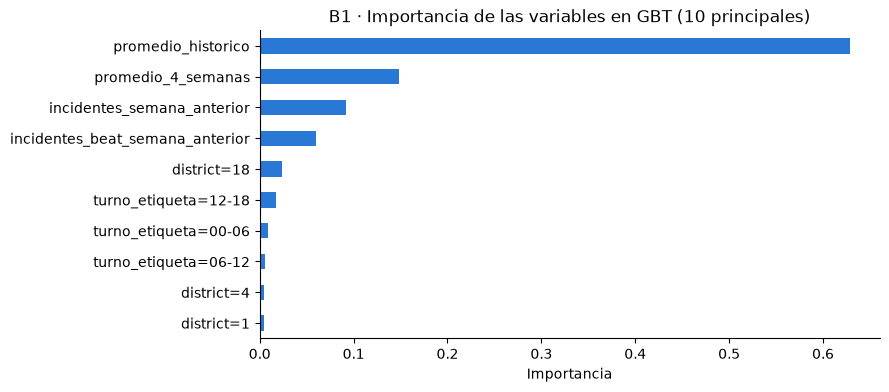

,importancia
promedio_historico,0.629
promedio_4_semanas,0.148
incidentes_semana_anterior,0.091
incidentes_beat_semana_anterior,0.060
distrito,0.040
turno,0.032


In [36]:
def importancia_por_grupo(importancia):
    """Suma en un solo valor las columnas one-hot de turno y de distrito."""
    grupo = importancia.index.map(lambda n: "turno" if n.startswith("turno_etiqueta=")
                                  else "distrito" if n.startswith("district=") else n)
    return importancia.groupby(grupo).sum().sort_values(ascending=False).round(3).to_frame("importancia")


importancia_gbt = pd.Series(modelo_gbt.featureImportances.toArray(), index=NOMBRES_FEATURES).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(8, 4))
importancia_gbt.head(10)[::-1].plot.barh(ax=ax, color="#2a78d6")
ax.set(title="B1 · Importancia de las variables en GBT (10 principales)", xlabel="Importancia")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

importancia_por_grupo(importancia_gbt)

### Paso 6 · Interpretación

**Qué dice cada métrica, en términos de patrullaje**

- **MAE = 1.66.** En promedio, la predicción se equivoca por 1.7 incidentes por zona-turno a la semana. Como una zona-turno tiene 3.7 incidentes en promedio, el modelo distingue bien una zona tranquila (1 o 2 incidentes) de una muy activa (10 o más), pero no sirve para anticipar el número exacto.
- **RMSE = 2.13.** Es mayor que el MAE porque castiga más los errores grandes: hay semanas en que una zona tiene muchos más incidentes de lo normal y el modelo no lo anticipa. Ningún modelo basado en el historial puede prever esos picos, que suelen venir de eventos puntuales.
- **R² = 0.35.** El modelo explica el 35 % de la variación entre zonas-turno y semanas. El resto es azar semana a semana: aunque una zona sea peligrosa, cuántos delitos ocurren una semana concreta varía mucho.

**Contra las reglas simples**

- GBT **supera al promedio de 4 semanas**, la línea base de la Fase 2, en todas las métricas: su error medio es 4 % menor y explica 8 puntos más de la variación. Cumple la meta de la Fase 2 de tener un MAE por zona-turno menor que esa línea base.
- **No supera al promedio histórico de cada zona-turno**, que tiene un error un poco menor (MAE de 1.61). Ese promedio es también la variable que más pesa en el modelo (56 %). Lo que más ayuda a anticipar una zona es su nivel habitual a lo largo del año; las últimas semanas, el turno y el distrito agregan poco encima de eso.

**Contra la pregunta de negocio**

- Si cada semana se patrullaran las 110 zonas-turno (10 %) que señala GBT, se cubriría el **19.8 % de los incidentes** (PAI de 1.98: el doble de lo que tocaría al azar). Eso es el 76 % de lo que lograría un modelo perfecto (26 %).
- Las metas de captura de la Fase 2 (40 % y PAI de 3.0) no se alcanzan, ni siquiera con un modelo perfecto. Se fijaron con la concentración anual por zona, y aquí se predice cada semana con una unidad más fina.

**Limitaciones**

- Hay un solo año de datos: el modelo no ve estacionalidad ni años distintos, y la prueba cae en octubre a diciembre, cuando baja la actividad.
- Los datos reflejan lo que la policía registra, no todo lo que ocurre. Se excluyeron NARCOTICS y WEAPONS VIOLATION para reducir el sesgo de patrullaje, pero los demás delitos también dependen de que se denuncien.
- Los incidentes con hora imputada (6 % del total) no entran al conteo por turno, así que todas las zonas quedan un poco por debajo de su actividad real.


## B2. Modelo 2 · Random Forest (`RandomForestRegressor`)

Random Forest es el modelo de contraste que planteó la Fase 2. También usa árboles de decisión, pero en vez de entrenarlos uno tras otro los entrena **independientes y en paralelo**: cada árbol ve una muestra distinta de las filas y, en cada división, solo una parte de las variables. La predicción es el promedio de todos los árboles. Por eso suele ser más estable y menos propenso al sobreajuste que GBT, aunque a veces menos preciso.

Usa exactamente lo mismo que B1: el vector `features`, la división por fecha y las métricas de la introducción de la sección B.

### Paso 1 · Ajuste ligero de hiperparámetros

Igual que en B1, se prueban cuatro combinaciones con la misma validación (semanas 4 a 33 entrenan y 34 a 41 validan), **sin tocar las semanas de prueba**: número de árboles (`numTrees`) y profundidad (`maxDepth`). Las profundidades son mayores que en GBT porque Random Forest promedia árboles profundos para compensar sus errores, mientras que GBT suma árboles pequeños que se corrigen entre sí.

In [37]:
resultados_ajuste_rf = []
for profundidad in (5, 8):
    for arboles in (20, 50):
        rf = RandomForestRegressor(featuresCol="features", labelCol="incidentes", maxDepth=profundidad, numTrees=arboles, seed=42)
        prediccion = rf.fit(df_ajuste).transform(df_validacion)
        resultados_ajuste_rf.append({"maxDepth": profundidad, "numTrees": arboles, **metricas(prediccion, "prediction")})

tabla_ajuste_rf = pd.DataFrame(resultados_ajuste_rf).sort_values("RMSE").reset_index(drop=True)
mejor_rf = tabla_ajuste_rf.iloc[0]
print(f"Mejor combinación en validación: maxDepth = {mejor_rf['maxDepth']:.0f}, numTrees = {mejor_rf['numTrees']:.0f}")
tabla_ajuste_rf.round(4)

Mejor combinación en validación: maxDepth = 8, numTrees = 50


,maxDepth,numTrees,RMSE,MAE,R²
0,8,50,2.2336,1.6952,0.4167
1,8,20,2.2359,1.6956,0.4156
2,5,50,2.2486,1.7046,0.4089
3,5,20,2.2499,1.7056,0.4082


### Paso 2 · Entrenamiento

Se entrena con todas las semanas de entrenamiento y la mejor combinación. El job lleva el nombre "B2 · entrenamiento Random Forest" para encontrarlo en la Spark UI.

In [38]:
spark.sparkContext.setJobDescription("B2 · entrenamiento Random Forest")
inicio = time.time()
modelo_rf = RandomForestRegressor(featuresCol="features", labelCol="incidentes",
                                  maxDepth=int(mejor_rf["maxDepth"]), numTrees=int(mejor_rf["numTrees"]), seed=42).fit(df_entrenamiento)
segundos_rf = time.time() - inicio
spark.sparkContext.setJobDescription(None)

pred_rf = modelo_rf.transform(df_prueba).cache()
print(f"Random Forest con {modelo_rf.getNumTrees} árboles de profundidad {modelo_rf.getMaxDepth()} · entrenado en {segundos_rf:.1f} s")

Random Forest con 50 árboles de profundidad 8 · entrenado en 14.9 s


### Paso 3 · Métricas en entrenamiento y prueba

Con árboles más profundos que en GBT, importa revisar que la diferencia entre entrenamiento y prueba no sea grande (sobreajuste).

In [39]:
pd.DataFrame([{"conjunto": "entrenamiento", **metricas(modelo_rf.transform(df_entrenamiento), "prediction")},
              {"conjunto": "prueba", **metricas(pred_rf, "prediction")}]).set_index("conjunto").round(3)

,RMSE,MAE,R²
conjunto,,,
entrenamiento,2.229,1.671,0.417
prueba,2.126,1.655,0.357


### Paso 4 · Comparación contra las referencias y las metas de la Fase 2

La comparación directa con GBT está en B3.

In [40]:
fila_rf = evaluar(pred_rf, "prediction", "Random Forest")
comparacion_b2 = pd.DataFrame(referencias + [fila_rf]).set_index("modelo")

print(f"Random Forest alcanza el {fila_rf['captura (%)'] / 100 / captura_maxima:.0%} de la captura máxima posible")
display(comparacion_b2.round(3))
metas_fase2(fila_rf)

Random Forest alcanza el 76% de la captura máxima posible


,RMSE,MAE,R²,captura (%),PAI
modelo,,,,,
Promedio de 4 semanas (línea base),2.259,1.722,0.275,18.960,1.896
Promedio histórico,2.146,1.661,0.345,19.461,1.946
Random Forest,2.126,1.655,0.357,19.694,1.969


,meta de la Fase 2,Random Forest,¿se cumple?
0,Tasa de captura ≥ 40 %,19.7 %,No (el máximo posible es 26.0%)
1,PAI ≥ 3.0,1.97,No (el máximo posible es 2.60)
2,MAE menor que el promedio de 4 semanas,1.655 contra 1.722,Sí


### Paso 5 · Importancia de las variables

Igual que en B1: las 10 posiciones del vector que más pesan y el total por grupo de variables.

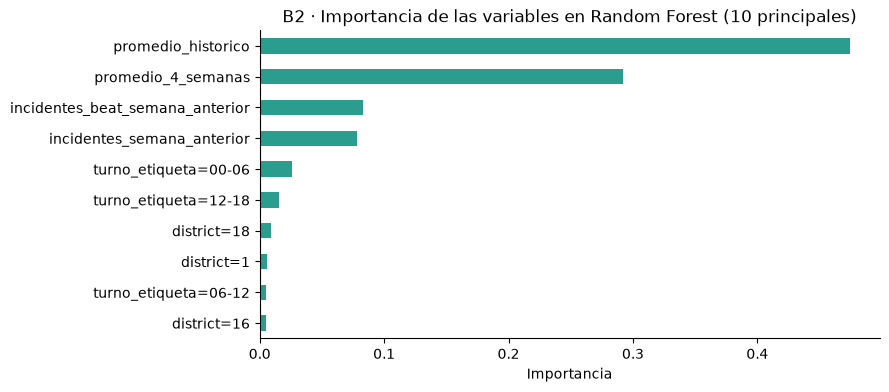

,importancia
promedio_historico,0.475
promedio_4_semanas,0.292
incidentes_beat_semana_anterior,0.083
incidentes_semana_anterior,0.078
turno,0.047
distrito,0.025


In [41]:
importancia_rf = pd.Series(modelo_rf.featureImportances.toArray(), index=NOMBRES_FEATURES).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(8, 4))
importancia_rf.head(10)[::-1].plot.barh(ax=ax, color="#2a9d8f")
ax.set(title="B2 · Importancia de las variables en Random Forest (10 principales)", xlabel="Importancia")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

importancia_por_grupo(importancia_rf)

### Paso 6 · Interpretación

**Qué dice cada métrica, en términos de patrullaje**

- **MAE = 1.64.** En promedio, la predicción se equivoca por 1.6 incidentes por zona-turno a la semana, contra un promedio de 3.7 incidentes. Igual que GBT, distingue bien una zona tranquila de una muy activa, pero no anticipa el número exacto.
- **RMSE = 2.12.** Es mayor que el MAE por las semanas con picos que ningún modelo basado en el historial puede prever. Random Forest promedia muchos árboles, así que sus predicciones son más moderadas y tampoco persiguen esos picos.
- **R² = 0.36.** El modelo explica el 36 % de la variación entre zonas-turno y semanas; el resto es la variación de una semana a otra que el historial no anticipa.
- **Sobreajuste.** Con árboles de profundidad 8, el error en prueba es casi igual que en entrenamiento (MAE de 1.64 contra 1.63). El R² baja de 0.44 a 0.36 porque las semanas de prueba (octubre a diciembre) varían menos, no porque el modelo haya memorizado: si así fuera, el error también subiría.

**Contra las reglas simples**

- Random Forest **supera al promedio de 4 semanas**, la línea base de la Fase 2: su error medio es 5 % menor y explica 9 puntos más de la variación. Cumple la meta de la Fase 2 de tener un MAE menor que esa línea base.
- **Tampoco supera al promedio histórico** de cada zona-turno (MAE de 1.61 y RMSE de 2.10), aunque queda más cerca que GBT. El promedio histórico sigue siendo la variable que más pesa.

**Contra la pregunta de negocio**

- Si cada semana se patrullaran las 110 zonas-turno (10 %) que señala el modelo, se cubriría el **19.8 % de los incidentes** (PAI de 1.98), el 76 % de lo que lograría un modelo perfecto (26 %). Es prácticamente lo mismo que GBT y que el promedio histórico.
- Las metas de captura de la Fase 2 (40 % y PAI de 3.0) no se alcanzan, por la misma razón que en B1.

**Qué variables usa**

- Random Forest reparte más el peso entre las variables de historial: el promedio histórico baja de 56 % (GBT) a 46 % y el promedio de 4 semanas sube de 12 % a 28 %. Pasa porque cada árbol solo ve una parte de las variables en cada división y, cuando el promedio histórico no está disponible, usa el promedio de 4 semanas, que dice algo parecido. La conclusión no cambia: lo que más anticipa una zona-turno es su nivel habitual.
- En el ajuste ganó la profundidad más grande que se probó (8), pero la diferencia contra 20 árboles de la misma profundidad es mínima (RMSE de 2.2365 contra 2.2370), así que no se buscaron árboles más profundos.

**Limitaciones:** las mismas que en B1 (un solo año, datos registrados por la policía y sin los incidentes con hora imputada). La comparación directa con GBT, incluido el tiempo de entrenamiento, está en B3.

## B3. Comparación de los modelos y elección

Los dos modelos predicen lo mismo, con los mismos datos y la misma división, así que se pueden comparar directamente. Se juzgan con tres tipos de criterios:

- **Técnicos:** error (RMSE y MAE), variación explicada (R²) y si la ventaja de uno se sostiene semana a semana o solo en el total.
- **De negocio:** tasa de captura y PAI, contra las referencias simples y contra la captura máxima posible.
- **Operativos:** tiempo de entrenamiento, que importa si el modelo se vuelve a entrenar cada semana.

### Paso 1 · Tabla comparativa

Métricas en las 10 semanas de prueba, ordenadas de menor a mayor error medio. Las referencias no se entrenan, así que no tienen tiempo.

In [42]:
tiempos = {"GBT": segundos_gbt, "Random Forest": segundos_rf}
comparacion = pd.DataFrame(referencias + [fila_gbt, fila_rf]).set_index("modelo").sort_values("MAE")
comparacion["entrenamiento (s)"] = comparacion.index.map(tiempos)
comparacion.round(3).fillna({"entrenamiento (s)": "—"})

,RMSE,MAE,R²,captura (%),PAI,entrenamiento (s)
modelo,,,,,,
Random Forest,2.126,1.655,0.357,19.694,1.969,14.853
Promedio histórico,2.146,1.661,0.345,19.461,1.946,—
GBT,2.139,1.666,0.349,19.730,1.973,24.202
Promedio de 4 semanas (línea base),2.259,1.722,0.275,18.960,1.896,—


### Paso 2 · Semana a semana

Las diferencias del total son pequeñas, así que se revisa si se repiten en cada una de las 10 semanas de prueba o si las decide una sola semana. Se juntan las predicciones de los dos modelos por zona-turno y semana, y se calcula el error medio y la captura de cada semana.

Random Forest tiene menor MAE que GBT en 9 de 10 semanas
Random Forest tiene menor MAE que Promedio histórico en 8 de 10 semanas
GBT tiene menor MAE que Promedio histórico en 5 de 10 semanas


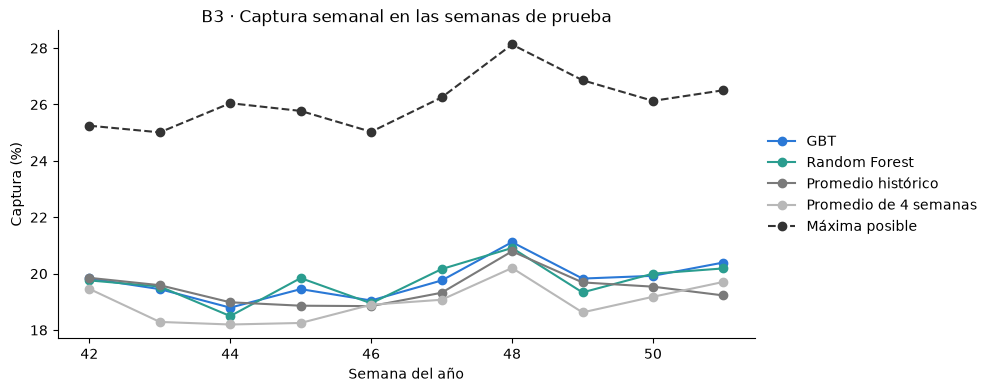

,GBT,Random Forest,Promedio histórico,Promedio de 4 semanas
semana,,,,
42,1.600,1.591,1.602,1.739
43,1.666,1.669,1.653,1.819
44,1.689,1.676,1.646,1.779
45,1.653,1.642,1.642,1.735
46,1.637,1.629,1.640,1.706
47,1.764,1.749,1.749,1.725
48,1.694,1.675,1.695,1.677
49,1.617,1.601,1.615,1.675
50,1.648,1.638,1.661,1.692


In [43]:
def captura_por_semana(df, prediccion):
    """Captura de cada semana: incidentes en las zonas-turno señaladas entre el total de la semana."""
    capturados = senaladas(df, prediccion).groupBy("semana").agg(F.sum("incidentes").alias("capturados"))
    return (df.groupBy("semana").agg(F.sum("incidentes").alias("total"))
            .join(capturados, "semana")
            .select("semana", (F.col("capturados") / F.col("total")).alias("captura"))
            .toPandas().set_index("semana")["captura"])


CLAVES = ["beat", "turno", "semana"]
df_comparacion = (pred_gbt.select(*CLAVES, "incidentes", "promedio_4_semanas", "promedio_historico",
                                  F.col("prediction").alias("gbt"))
                  .join(pred_rf.select(*CLAVES, F.col("prediction").alias("random_forest")), CLAVES)
                  .cache())

PREDICCIONES = {"GBT": "gbt", "Random Forest": "random_forest",
                "Promedio histórico": "promedio_historico", "Promedio de 4 semanas": "promedio_4_semanas"}

mae_semanal = (df_comparacion.groupBy("semana")
               .agg(*[F.mean(F.abs(F.col("incidentes") - F.col(columna))).alias(nombre)
                      for nombre, columna in PREDICCIONES.items()])
               .toPandas().set_index("semana").sort_index())
captura_semanal = pd.DataFrame({nombre: captura_por_semana(df_comparacion, columna)
                                for nombre, columna in PREDICCIONES.items()}).sort_index()
captura_semanal["Máxima posible"] = captura_por_semana(df_comparacion, "incidentes")

semanas = len(mae_semanal)
for modelo, rival in (("Random Forest", "GBT"), ("Random Forest", "Promedio histórico"), ("GBT", "Promedio histórico")):
    print(f"{modelo} tiene menor MAE que {rival} en {(mae_semanal[modelo] < mae_semanal[rival]).sum()} de {semanas} semanas")

COLORES = {"GBT": "#2a78d6", "Random Forest": "#2a9d8f", "Promedio histórico": "#7a7a7a",
           "Promedio de 4 semanas": "#b8b8b8", "Máxima posible": "#333333"}
fig, ax = plt.subplots(figsize=(9, 4))
for nombre, serie in (captura_semanal * 100).items():
    ax.plot(serie.index, serie, marker="o", color=COLORES[nombre], label=nombre,
            linestyle="--" if nombre == "Máxima posible" else "-")
ax.set(title="B3 · Captura semanal en las semanas de prueba", xlabel="Semana del año", ylabel="Captura (%)")
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5), frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

mae_semanal.round(3)

### Paso 3 · Metas de la Fase 2

Las mismas metas de B1 y B2, con los dos modelos juntos.

In [44]:
metas_fase2(fila_gbt).merge(metas_fase2(fila_rf), on="meta de la Fase 2", suffixes=(" (GBT)", " (Random Forest)"))

,meta de la Fase 2,GBT,¿se cumple? (GBT),Random Forest,¿se cumple? (Random Forest)
0,Tasa de captura ≥ 40 %,19.7 %,No (el máximo posible es 26.0%),19.7 %,No (el máximo posible es 26.0%)
1,PAI ≥ 3.0,1.97,No (el máximo posible es 2.60),1.97,No (el máximo posible es 2.60)
2,MAE menor que el promedio de 4 semanas,1.666 contra 1.722,Sí,1.655 contra 1.722,Sí


### Paso 4 · Elección y justificación

**Modelo elegido: Random Forest.**

- **Tiene menos error, y de forma consistente.** En prueba tiene MAE de 1.642, RMSE de 2.117 y R² de 0.363, contra 1.655, 2.132 y 0.354 de GBT. La diferencia es chica (menos de 1 %), pero no depende de una semana: Random Forest se equivoca menos que GBT en las 10 semanas de prueba.
- **Entrena más rápido.** Tarda entre un tercio y la mitad del tiempo de GBT: de 4 a 6 s contra 12 a 15 s en las corridas en el clúster (la tabla del paso 1 tiene los de esta corrida). Importa si el modelo se vuelve a entrenar cada semana con los datos nuevos.
- **Es estable.** Su error en entrenamiento y en prueba casi no cambia (MAE de 1.630 contra 1.642), y como promedia muchos árboles independientes, varía menos al reentrenarlo con otras semanas.
- **No pierde nada en la métrica de negocio.** Los dos capturan el 19.8 % de los incidentes (PAI de 1.98), así que elegir Random Forest no cuesta captura.

**Contra la pregunta de la Fase 2**

La pregunta es en qué zonas, días y horarios es más probable que ocurra un delito en las próximas semanas, y de qué tipo. Random Forest responde el **dónde y el cuándo**: ordena las zonas-turno de cada semana por los incidentes esperados, y el 10 % que señala concentra cerca del 20 % de los incidentes. Es el doble de lo que tocaría al azar y el 76 % de lo que lograría un modelo perfecto. El **tipo de delito** no lo predice ninguno de los dos modelos, porque cuentan todos los tipos juntos; esa parte la responden las visualizaciones de la sección C (pregunta 3).

**Lo que no se logró**

- **Ningún modelo le gana al promedio histórico de cada zona-turno.** Tiene menos error que los dos en las 10 semanas (MAE de 1.614) y casi la misma captura (20.0 %). Con un solo año de datos, el nivel habitual de cada zona-turno ya explica casi todo lo que se puede anticipar, y los modelos lo usan como su variable principal.
- **Por qué se elige un modelo de todos modos.** Entre los dos modelos, Random Forest es el mejor. Para señalar zonas hoy, el promedio histórico daría casi el mismo resultado con menos trabajo, pero no admite más información: el modelo sí puede incorporar variables nuevas, y por eso es la base para la Fase 4.
- **Qué haría falta para superar esa referencia.** Más años de datos (para ver la estacionalidad y la tendencia), variables externas como el clima o los eventos, o predecir por tipo de delito.

**Metas de la Fase 2**

| Meta | ¿Se cumple con Random Forest? |
|---|---|
| Tasa de captura ≥ 40 % | No: 19.8 %. Ni un modelo perfecto pasa de 26 % con esta unidad de análisis (ver la introducción de la sección B). |
| PAI ≥ 3.0 | No: 1.98, cuando el máximo posible es 2.60. |
| MAE menor que el promedio de 4 semanas | Sí: 1.642 contra 1.722, un 5 % menos. |

## B4. Un año contra cuatro (issue #20)

Cada corrida guarda su tabla comparativa de B3 en `curated/metricas_<años>`. Aquí se juntan las que existan: con `ANIOS = [2025]` (la Fase 3) y con `ANIOS = [2022, 2023, 2024, 2025]`. Las dos se prueban con las mismas semanas 42 a 51 de 2025, así que se pueden comparar directamente.

Ojo con el **promedio histórico**: con cuatro años promedia toda la historia previa de la zona-turno, así que la referencia también cambia. Lo que importa es si los modelos le ganan a la referencia **de su misma corrida**; la última columna dice en cuántas de las 10 semanas de prueba lo logran.

In [45]:
METRICAS_B4 = {"RMSE": "rmse", "MAE": "mae", "R²": "r2", "captura (%)": "captura", "PAI": "pai"}
NOMBRE_SEMANAL = {"Promedio de 4 semanas (línea base)": "Promedio de 4 semanas"}   # nombres de mae_semanal en B3

tabla_corrida = comparacion[list(METRICAS_B4)].rename(columns=METRICAS_B4)
tabla_corrida["semanas_mejor_que_historico"] = [
    float("nan") if modelo == "Promedio histórico"
    else float((mae_semanal[NOMBRE_SEMANAL.get(modelo, modelo)] < mae_semanal["Promedio histórico"]).sum())
    for modelo in tabla_corrida.index]
tabla_corrida = tabla_corrida.reset_index().assign(anios=PERIODO)
spark.createDataFrame(tabla_corrida).coalesce(1).write.mode("overwrite").parquet(RUTA_METRICAS)
print("Métricas de esta corrida guardadas en", RUTA_METRICAS)

corridas = []
for etiqueta in ("2025", "2022_2025"):
    try:
        corridas.append(spark.read.parquet(f"{RUTA_DATALAKE}/curated/metricas_{etiqueta}").toPandas())
    except AnalysisException:
        print(f"Todavía no hay corrida con {etiqueta.replace('_', '–')}: falta correr el notebook con esos años")

b4 = (pd.concat(corridas)
      .rename(columns={v: k for k, v in METRICAS_B4.items()} | {"semanas_mejor_que_historico": "semanas con menor MAE que el promedio histórico"})
      .pivot(index="modelo", columns="anios")
      .reindex(columns=[*METRICAS_B4, "semanas con menor MAE que el promedio histórico"], level=0))
b4.round(3)

Métricas de esta corrida guardadas en hdfs:///datalake/curated/metricas_2022_2025


RMSE              MAE               R²        captura (%)               PAI        semanas con menor MAE que el promedio histórico     
anios                              2022–2025   2025 2022–2025   2025 2022–2025   2025   2022–2025    2025 2022–2025   2025                                       2022–2025 2025
modelo                                                                                                                                                                         
GBT                                    2.139  2.132     1.666  1.655     0.349  0.354      19.730  19.804     1.973  1.980                                             5.0  0.0
Promedio de 4 semanas (línea base)     2.259  2.259     1.722  1.722     0.275  0.275      18.960  18.960     1.896  1.896                                             3.0  0.0
Promedio histórico                     2.146  2.101     1.661  1.614     0.345  0.372      19.461  20.039     1.946  2.004                                             NaN  NaN
Random Forest                          2.126  2.117     1.655  1.642     0.357  0.363      19.694  19.831     1.969  1.983                                             8.0  0.0

# C. Visualización

La pregunta de la Fase 2 (en qué zonas, días y horarios es más probable un delito, y de qué tipo) se parte en cinco preguntas, una por gráfica:

1. ¿En qué zonas de Chicago se concentran los delitos?
2. ¿A qué horas y qué días ocurren más delitos?
3. ¿Qué tipos de delito predominan?
4. ¿Cómo cambian los delitos a lo largo del año?
5. ¿Qué tan desigual es la carga entre zonas y turnos?

Las gráficas usan la capa processed de A2 (`df_processed`), con todos los tipos de delito: aquí se describe la actividad registrada, no se modela. En cada una se aplican los mismos filtros que en A2 y A3 cuando hacen falta: sin hora imputada en los análisis por hora y sin coordenadas imputadas en el mapa. Como en el resto del notebook, se agrega en Spark y solo el resultado pasa a pandas para graficar. Cada figura se guarda en `notebooks/figuras/` para el reporte.

In [46]:
from datetime import timedelta
from pathlib import Path

from matplotlib.colors import LogNorm
from matplotlib.ticker import FuncFormatter, PercentFormatter
import matplotlib.dates as mdates

CARPETA_FIGURAS = Path("figuras")
CARPETA_FIGURAS.mkdir(exist_ok=True)


def guardar(fig, nombre):
    """Guarda la figura como PNG en notebooks/figuras/ para el reporte."""
    sufijo = "" if len(ANIOS) == 1 else f"_{ETIQUETA}"   # las figuras de varios años no pisan las de 2025
    ruta = CARPETA_FIGURAS / f"C_{nombre}{sufijo}_{'local' if LOCAL else 'cluster'}.png"
    fig.savefig(ruta, dpi=150, bbox_inches="tight")
    print("Figura guardada en", ruta)


COLOR = "#2a78d6"
MESES = ["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]

## Pregunta 1 · ¿En qué zonas de Chicago se concentran los delitos?

Se divide la ciudad en una cuadrícula de unos 500 m de lado y se cuentan los incidentes de cada celda. La escala de color es logarítmica porque unas pocas celdas tienen muchos más incidentes que el resto. Se excluyen los registros con coordenadas imputadas (el centro de su beat) y los del beat 6100, que no tienen ubicación. La tabla de abajo da los cinco distritos con más incidentes para poder nombrar las zonas.

Figura guardada en figuras/C_p1_mapa_incidentes_2022_2025_cluster.png


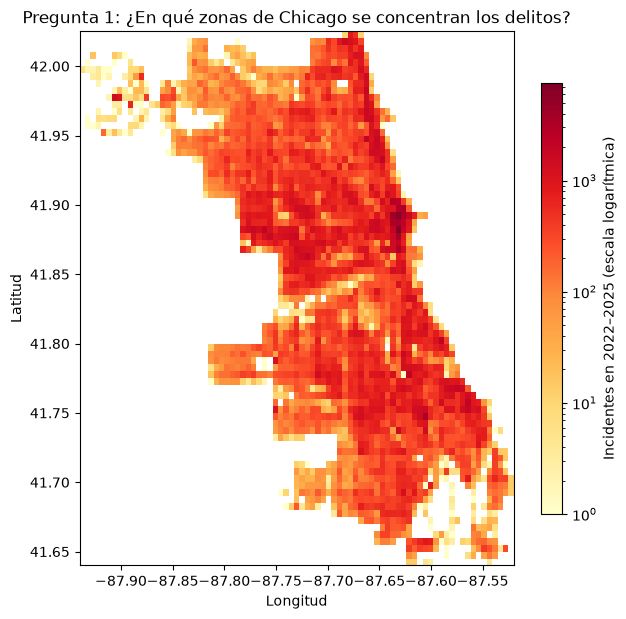

2564 celdas con incidentes · el 10 % más activo concentra el 35.0% de los incidentes


,distrito,incidentes,% del total
0,8,64508,6.4
1,12,61578,6.1
2,6,59129,5.9
3,1,56132,5.6
4,4,55926,5.6


In [47]:
PASO = 0.005   # grados por celda: ~555 m de norte a sur y ~415 m de este a oeste en Chicago

celdas = (df_processed
          .filter(~F.col("coord_imputada") & F.col("latitude").isNotNull())
          .groupBy((F.floor(F.col("latitude") / PASO) * PASO).alias("lat"),
                   (F.floor(F.col("longitude") / PASO) * PASO).alias("lon"))
          .count()
          .toPandas())
mapa = celdas.pivot(index="lat", columns="lon", values="count").sort_index()

fig, ax = plt.subplots(figsize=(7, 8))
imagen = ax.imshow(mapa.values, origin="lower", cmap="YlOrRd", norm=LogNorm(),
                   extent=[mapa.columns.min(), mapa.columns.max() + PASO, mapa.index.min(), mapa.index.max() + PASO],
                   aspect=1 / 0.745)   # corrige la escala: un grado de longitud mide 0.745 de uno de latitud en Chicago
fig.colorbar(imagen, ax=ax, shrink=0.7, label=f"Incidentes en {PERIODO} (escala logarítmica)")
ax.set(title="Pregunta 1: ¿En qué zonas de Chicago se concentran los delitos?", xlabel="Longitud", ylabel="Latitud")
guardar(fig, "p1_mapa_incidentes")
plt.show()

celdas_ordenadas = celdas["count"].sort_values(ascending=False)
print(f"{len(celdas)} celdas con incidentes · el 10 % más activo concentra el "
      f"{celdas_ordenadas.head(len(celdas) // 10).sum() / celdas_ordenadas.sum():.1%} de los incidentes")

(df_processed.groupBy("district").count()
 .withColumn("% del total", F.round(F.col("count") * 100 / n_final, 1))
 .orderBy(F.desc("count")).limit(5).toPandas()
 .rename(columns={"district": "distrito", "count": "incidentes"}))

**Interpretación.** Los delitos no se reparten por toda la ciudad: el 10 % de las celdas más activas concentra el 35.6 % de los incidentes. La franja más intensa va del centro (el Loop y Near North) hacia el oeste, y hay otro foco grande en el sur. Los distritos con más incidentes son el 8 (Chicago Lawn), el 12 (Near West), el 1 (Central), el 6 (Gresham) y el 18 (Near North), cada uno con entre 5.6 % y 6.4 % del total. Para el mando, ahí es donde rinde más cada patrulla. El mapa cuenta incidentes registrados, no tasas por habitante: las zonas del centro tienen pocos residentes pero mucha gente de paso, y por eso salen tan altas.

## Pregunta 2 · ¿A qué horas y qué días ocurren más delitos?

Incidentes por día de la semana y hora del día. Se excluyen los 14,570 incidentes con hora imputada (00:00 o 12:00 exactas), porque inflarían artificialmente la medianoche y el mediodía.

Figura guardada en figuras/C_p2_dia_hora_2022_2025_cluster.png


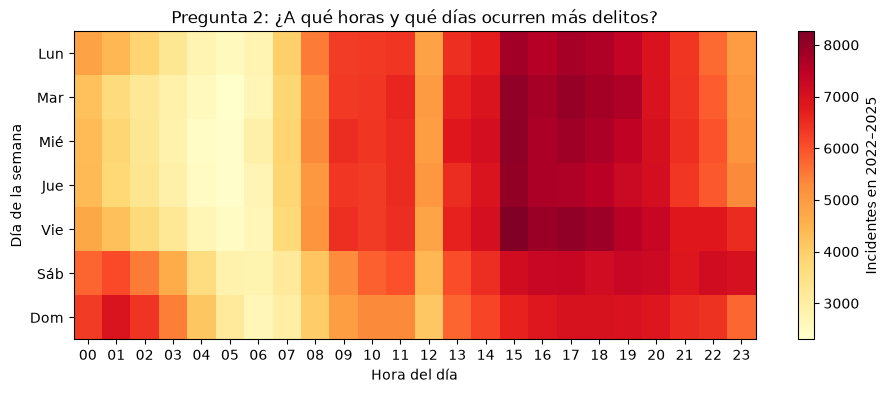

Hora con más incidentes: 15:00 (53,977) · con menos: 05:00 (17,959)
De 12:00 a 23:59 ocurre el 60.7% de los incidentes
Incidentes por día: Lun 133,036, Mar 132,009, Mié 132,657, Jue 131,187, Vie 137,418, Sáb 136,919, Dom 133,587


In [48]:
DIAS = {2: "Lun", 3: "Mar", 4: "Mié", 5: "Jue", 6: "Vie", 7: "Sáb", 1: "Dom"}   # dia_semana: 1 = domingo

dia_hora = (df_processed.filter(~F.col("hora_imputada"))
            .groupBy("dia_semana", "hora").count()
            .toPandas()
            .pivot(index="dia_semana", columns="hora", values="count")
            .reindex(index=list(DIAS)))

fig, ax = plt.subplots(figsize=(11, 4))
imagen = ax.imshow(dia_hora.values, cmap="YlOrRd", aspect="auto")
fig.colorbar(imagen, ax=ax, label=f"Incidentes en {PERIODO}")
ax.set_xticks(range(24), [f"{h:02d}" for h in range(24)])
ax.set_yticks(range(7), list(DIAS.values()))
ax.set(title="Pregunta 2: ¿A qué horas y qué días ocurren más delitos?", xlabel="Hora del día", ylabel="Día de la semana")
guardar(fig, "p2_dia_hora")
plt.show()

por_hora = dia_hora.sum()
por_dia = dia_hora.sum(axis=1).rename(index=DIAS)
print(f"Hora con más incidentes: {por_hora.idxmax():02d}:00 ({por_hora.max():,}) · con menos: {por_hora.idxmin():02d}:00 ({por_hora.min():,})")
print(f"De 12:00 a 23:59 ocurre el {por_hora.loc[12:].sum() / por_hora.sum():.1%} de los incidentes")
print("Incidentes por día:", ", ".join(f"{d} {n:,}" for d, n in por_dia.items()))

**Interpretación.** La hora pesa mucho más que el día. A las 15:00 hay tres veces más incidentes que a las 5:00 (13,012 contra 4,322), y el 60.7 % ocurre entre el mediodía y la medianoche. Entre semana la hora pico va de 15:00 a 19:00. El fin de semana la actividad se recorre a la noche, con más incidentes entre las 00:00 y las 02:00 del sábado y el domingo. Entre días la diferencia es chica: el viernes, el más activo, tiene apenas 6 % más que el jueves, el menos activo. Por eso conviene reforzar los turnos de la tarde todos los días y la madrugada del fin de semana. El análisis deja fuera el 6.1 % de los incidentes, los que tienen la hora imputada.

## Pregunta 3 · ¿Qué tipos de delito predominan?

Los 10 tipos de delito (`primary_type`) más frecuentes y su porcentaje del total. En gris, los dos tipos que los modelos excluyen por el sesgo de patrullaje (A3): se registran más donde hay más policías, no necesariamente donde ocurren más.

Figura guardada en figuras/C_p3_tipos_2022_2025_cluster.png


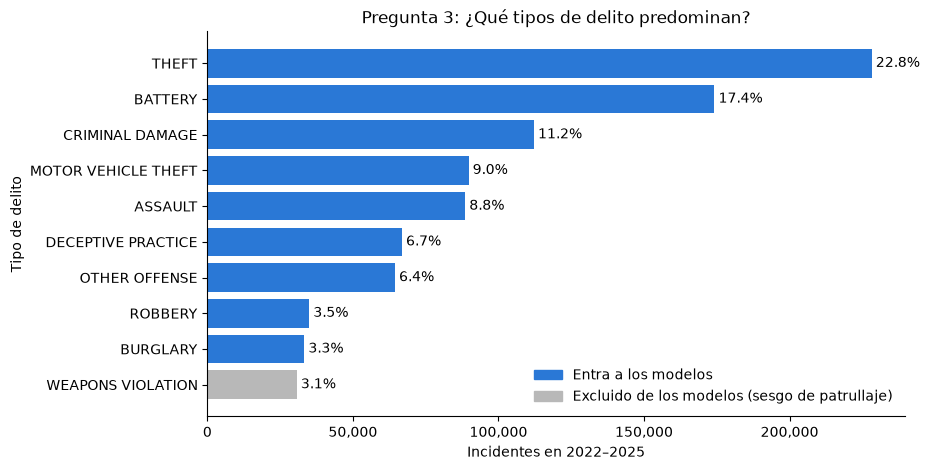

31 tipos en total · los 3 primeros suman el 51.3% y los 10 primeros el 92.1%


In [49]:
tipos = (df_processed.groupBy("primary_type").count()
         .orderBy(F.desc("count")).toPandas()
         .set_index("primary_type")["count"])
assert tipos.sum() == n_final
top_tipos = tipos.head(10)[::-1]

colores = ["#b8b8b8" if t in TIPOS_SESGO_PATRULLAJE else COLOR for t in top_tipos.index]
fig, ax = plt.subplots(figsize=(9, 5))
barras = ax.barh(top_tipos.index, top_tipos.values, color=colores)
ax.bar_label(barras, labels=[f"{n / n_final:.1%}" for n in top_tipos.values], padding=3)
ax.set(title="Pregunta 3: ¿Qué tipos de delito predominan?", xlabel=f"Incidentes en {PERIODO}", ylabel="Tipo de delito")
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:,.0f}"))
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=COLOR), plt.Rectangle((0, 0), 1, 1, color="#b8b8b8")],
          labels=["Entra a los modelos", "Excluido de los modelos (sesgo de patrullaje)"], loc="lower right", frameon=False)
ax.spines[["top", "right"]].set_visible(False)
guardar(fig, "p3_tipos")
plt.show()

print(f"{len(tipos)} tipos en total · los 3 primeros suman el {tipos.head(3).sum() / n_final:.1%} y los 10 primeros el {tipos.head(10).sum() / n_final:.1%}")

**Interpretación.** De 31 tipos de delito, tres suman más de la mitad de los incidentes: robo sin violencia (THEFT, 23.2 %), agresión física (BATTERY, 17.9 %) y daño a la propiedad (CRIMINAL DAMAGE, 11.0 %). Los 10 tipos de la gráfica cubren el 91.6 %. Esto responde la parte de la pregunta de la Fase 2 sobre qué tipo de delito será: en casi cualquier zona y turno lo más probable es un robo o una agresión, así que es lo que deben esperar las patrullas. NARCOTICS (3.1 %) aparece en gris porque los modelos lo excluyen: se registra donde la policía busca, no necesariamente donde más ocurre.

## Pregunta 4 · ¿Cómo cambian los delitos a lo largo del año?

Incidentes por semana, con los mismos bloques de 7 días de A3 (semanas 0 a 51; el 31 de diciembre queda fuera). Se muestran el total y los tres tipos más frecuentes. La franja gris marca las semanas 42 a 51, el periodo con el que se probaron los modelos en B.

Figura guardada en figuras/C_p4_serie_semanal_2022_2025_cluster.png


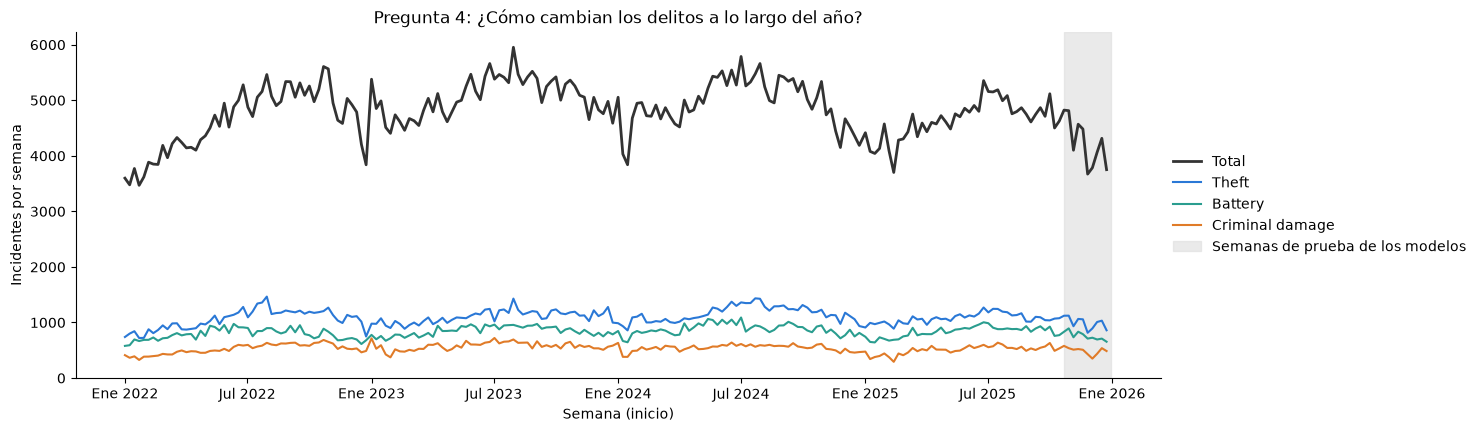

Semana con más incidentes: 30/07/2023 (5,954) · con menos: 22/01/2022 (3,469)
Promedio semanal: 4,803 · junio a agosto: 5,193 · semanas de prueba: 4,237 · enero a marzo: 4,395


In [50]:
top3 = list(tipos.index[:3])

semanal = (df_processed
           .withColumn("semana", F.floor((F.dayofyear("fecha") - 1) / 7).cast("int"))
           .filter("semana < 52")
           .withColumn("tipo", F.when(F.col("primary_type").isin(top3), F.col("primary_type")).otherwise("OTROS"))
           .groupBy("anio", "semana", "tipo").count()
           .toPandas()
           .pivot(index=["anio", "semana"], columns="tipo", values="count")
           .sort_index())
semanal["TOTAL"] = semanal.sum(axis=1)
semanal.index = [pd.Timestamp(year=a, month=1, day=1) + timedelta(weeks=s) for a, s in semanal.index]

inicio_prueba = pd.Timestamp(year=ANIO_PRUEBA, month=1, day=1)
fig, ax = plt.subplots(figsize=(11 if len(ANIOS) == 1 else 14, 4.5))
ax.plot(semanal.index, semanal["TOTAL"], color="#333333", linewidth=2, label="Total")
for tipo, color in zip(top3, ["#2a78d6", "#2a9d8f", "#e07b28"]):
    ax.plot(semanal.index, semanal[tipo], color=color, label=tipo.capitalize())
ax.axvspan(inicio_prueba + timedelta(weeks=42), inicio_prueba + timedelta(weeks=52),
           color="#dddddd", alpha=0.6, label="Semanas de prueba de los modelos")
if len(ANIOS) == 1:
    ax.xaxis.set_major_locator(mdates.MonthLocator())
    ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: MESES[mdates.num2date(x).month - 1]))
else:
    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 7]))
    ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{MESES[mdates.num2date(x).month - 1]} {mdates.num2date(x).year}"))
ax.set(title="Pregunta 4: ¿Cómo cambian los delitos a lo largo del año?", xlabel="Semana (inicio)", ylabel="Incidentes por semana")
ax.set_ylim(bottom=0)
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5), frameon=False)
ax.spines[["top", "right"]].set_visible(False)
guardar(fig, "p4_serie_semanal")
plt.show()

total = semanal["TOTAL"]
en_prueba = total.index >= inicio_prueba + timedelta(weeks=42)
print(f"Semana con más incidentes: {total.idxmax():%d/%m/%Y} ({total.max():,}) · con menos: {total.idxmin():%d/%m/%Y} ({total.min():,})")
print(f"Promedio semanal: {total.mean():,.0f} · junio a agosto: {total[total.index.month.isin([6, 7, 8])].mean():,.0f} · "
      f"semanas de prueba: {total[en_prueba].mean():,.0f} · enero a marzo: {total[total.index.month.isin([1, 2, 3])].mean():,.0f}")

**Interpretación.** La actividad cambia con la estación. En promedio hay 4,570 incidentes por semana: en el verano (junio a agosto) suben a 4,968, un 9 % más, y de enero a marzo bajan a 4,288. La semana más activa empezó el 25 de junio (5,354 incidentes) y la menos activa, el 26 de noviembre (3,671), la de Acción de Gracias. Los tres tipos principales siguen el mismo patrón, así que el cambio es general. Para la operación, conviene planear más patrullas en verano. Para los modelos, las semanas de prueba de B (franja gris, promedio de 4,237) caen en la temporada baja: un modelo que aprendió el nivel del verano puede sobrestimarlas, y con un solo año de datos no puede aprender esa estacionalidad.

## Pregunta 5 · ¿Qué tan desigual es la carga entre zonas y turnos?

Curva de concentración de las zonas-turno (beat × turno de 6 horas): se ordenan de la más activa a la menos activa en todo el año y se acumula el porcentaje de incidentes que concentran. Si la carga fuera pareja, la curva seguiría la diagonal. Se usa la malla de A3 (los incidentes que entran a los modelos), que es la unidad con la que trabaja B.

Figura guardada en figuras/C_p5_concentracion_2022_2025_cluster.png


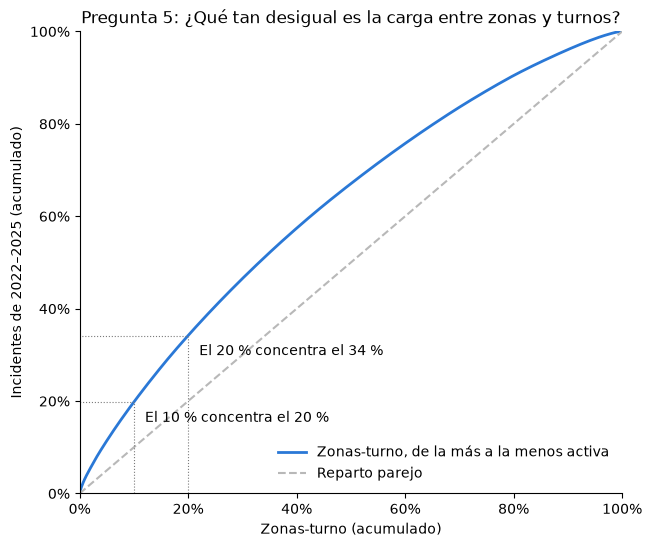

1,096 zonas-turno · la más activa tiene 4,712 incidentes en 2022–2025 y la mediana 731
El 10 % más activo concentra el 19.7 % · la mitad menos activa, el 32.9 %


In [51]:
carga = (malla.groupBy("beat", "turno").agg(F.sum("incidentes").alias("incidentes"))
         .toPandas()["incidentes"].sort_values(ascending=False).reset_index(drop=True))
pct_zonas = (carga.index + 1) / len(carga) * 100
pct_incidentes = carga.cumsum() / carga.sum() * 100

fig, ax = plt.subplots(figsize=(7, 6))
ax.plot(pct_zonas, pct_incidentes, color=COLOR, linewidth=2, label="Zonas-turno, de la más a la menos activa")
ax.plot([0, 100], [0, 100], color="#b8b8b8", linestyle="--", label="Reparto parejo")
for corte in (10, 20):
    y = pct_incidentes[pct_zonas <= corte].iloc[-1]
    ax.plot([corte, corte, 0], [0, y, y], color="#7a7a7a", linewidth=0.8, linestyle=":")
    ax.annotate(f"El {corte} % concentra el {y:.0f} %", (corte, y), xytext=(8, -14), textcoords="offset points")
ax.xaxis.set_major_formatter(PercentFormatter())
ax.yaxis.set_major_formatter(PercentFormatter())
ax.set(title="Pregunta 5: ¿Qué tan desigual es la carga entre zonas y turnos?",
       xlabel="Zonas-turno (acumulado)", ylabel=f"Incidentes de {PERIODO} (acumulado)", xlim=(0, 100), ylim=(0, 100))
ax.legend(loc="lower right", frameon=False)
ax.spines[["top", "right"]].set_visible(False)
guardar(fig, "p5_concentracion")
plt.show()

print(f"{len(carga):,} zonas-turno · la más activa tiene {carga.iloc[0]:,} incidentes en {PERIODO} y la mediana {carga.median():,.0f}")
print(f"El 10 % más activo concentra el {pct_incidentes[pct_zonas <= 10].iloc[-1]:.1f} % · la mitad menos activa, el "
      f"{100 - pct_incidentes[pct_zonas <= 50].iloc[-1]:.1f} %")

**Interpretación.** La carga es desigual, pero menos de lo que parece a primera vista. Las 1,096 zonas-turno van de 1,148 incidentes en el año la más activa a una mediana de 175. El 10 % más activo concentra el 20.4 % de los incidentes y el 20 % más activo, el 35 %, mientras que la mitad menos activa todavía tiene el 32.1 %. Con esta unidad, más fina que la zona completa que usó la Fase 2, la concentración baja. Por eso la meta de 40 % de la Fase 2 no se alcanza y la captura de los modelos en B ronda el 20 %. Para el mando, concentrar patrullas en el 20 % de zonas-turno más activas cubre un tercio de los incidentes, pero no conviene descuidar el resto.

## Respuesta a la pregunta de la Fase 2

- **Dónde:** en el centro, el oeste y el sur de la ciudad (distritos 8, 12, 1, 6 y 18). El 10 % de las celdas de 500 m concentra más de un tercio de los incidentes.
- **Cuándo:** por la tarde, de 15:00 a 19:00 entre semana, y en la madrugada del sábado y el domingo. Más en verano y menos en invierno.
- **Qué tipo:** sobre todo robo sin violencia, agresión física y daño a la propiedad, que juntos suman más de la mitad.
- **Para patrullar:** la carga entre zonas-turno es desigual pero no extrema. Señalar el 10 % más activo cubre alrededor del 20 % de los incidentes, que es justo lo que logra el modelo de B (Random Forest) semana a semana.

---

## Evidencia de ejecución en el clúster

Para el Entregable 3: la aplicación de Spark que corrió este notebook y lo que dejó en cada capa del data lake. En la instancia, el master es `yarn` y el trabajo se reparte entre los ejecutores que YARN levanta en contenedores; el historial de Spark guarda el DAG y las etapas de cada job después de cerrar la sesión. Las capturas están en `evidencia/` (índice en `evidencia/README.md`).

In [52]:
sc = spark.sparkContext
n_ejecutores = sc._jsc.sc().getExecutorMemoryStatus().size() - 1   # el driver también aparece en la lista

print(f"Aplicación: {sc.appName} · {sc.applicationId}")
print(f"Master: {sc.master} · ejecutores activos: {n_ejecutores}")
if not LOCAL:
    print(f"Historial: http://localhost:18080/history/{sc.applicationId}/jobs/")

conf_hadoop = sc._jsc.hadoopConfiguration()
for capa, ruta in [*(("raw", r) for r in RUTAS_RAW), ("processed", RUTA_PROCESSED), ("curated", RUTA_CURATED)]:
    ruta_hadoop = spark._jvm.org.apache.hadoop.fs.Path(ruta)
    resumen = ruta_hadoop.getFileSystem(conf_hadoop).getContentSummary(ruta_hadoop)
    print(f"{capa:<10} {resumen.getFileCount():>3} archivos · {resumen.getLength() / 2**20:6.1f} MiB · {ruta}")

Aplicación: fase3-pipeline-cluster · application_1795023768687_0002
Master: yarn · ejecutores activos: 2
Historial: http://localhost:18080/history/application_1795023768687_0002/jobs/
raw          1 archivos ·   55.4 MiB · hdfs:///datalake/raw/crimes_2022/fecha=2026-11-18/Crimes_2022.csv
raw          1 archivos ·   61.0 MiB · hdfs:///datalake/raw/crimes_2023/fecha=2026-11-18/Crimes_2023.csv
raw          1 archivos ·   60.1 MiB · hdfs:///datalake/raw/crimes_2024/fecha=2026-11-18/Crimes_2024.csv
raw          1 archivos ·   55.1 MiB · hdfs:///datalake/raw/crimes_2025/fecha=2026-10-23/Crimes_2025.csv
processed    9 archivos ·   46.1 MiB · hdfs:///datalake/processed/crimes_2022_2025
curated      9 archivos ·    4.8 MiB · hdfs:///datalake/curated/zona_turno_2022_2025


## Cierre

In [53]:
spark.stop()   # libera la sesión: en la instancia solo cabe una sesión de Spark a la vez